# Problématique



<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>énoncé :</strong> 
    Vous voulez tenter de prédire les émissions de CO2 et la consommation totale d’énergie de bâtiments non destinés à l’habitation pour lesquels elles n’ont pas encore été mesurées.<br>Votre prédiction se basera sur les données structurelles des bâtiments (taille et usage des bâtiments, date de construction, situation géographique, ...)<br><br> L’objectif est de te passer des relevés de consommation annuels futurs (attention à la fuite de données). Nous ferons de toute façon pour tout nouveau bâtiment un premier relevé de référence la première année, donc rien ne t'interdit d’en déduire des variables structurelles aux bâtiments, par exemple la nature et proportions des sources d’énergie utilisées.. 
        </p>


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>énoncé :</strong>Vous cherchez également à évaluer l’intérêt de l’"ENERGY STAR Score" pour la prédiction d’émissions, qui est fastidieux à calculer avec l’approche utilisée actuellement par votre équipe. Vous l'intégrerez dans la modélisation et jugerez de son intérêt. </p>

https://data.seattle.gov/dataset/2016-Building-Energy-Benchmarking/2bpz-gwpy

# Librairies

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.width',800)
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',800)

# Source

Updated
April 20, 2021
Data Provided by
City of Seattle

# Dataset

In [3]:
data = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

In [4]:
data.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

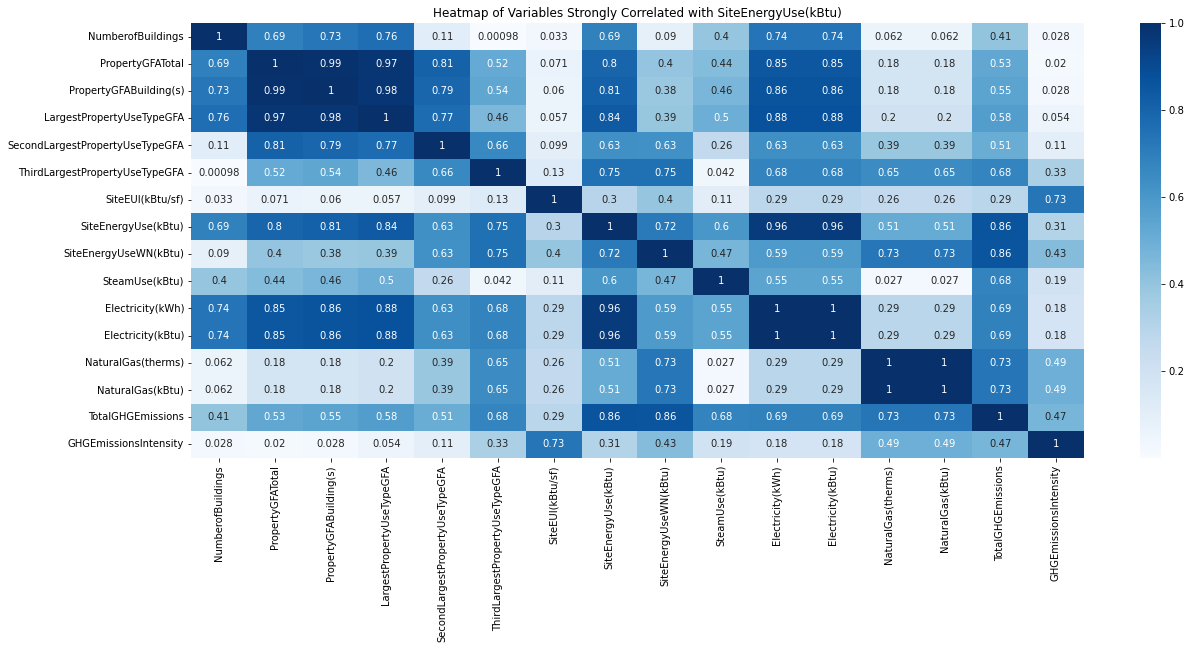

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Créer une matrice de corrélation
corr_matrix = data.corr()

# Obtenir les corrélations absolues avec la variable cible 'SiteEnergyUse(kBtu)'
correlations_target = abs(corr_matrix["SiteEnergyUse(kBtu)"])

# Filtrer les variables qui ont une corrélation supérieure à un certain seuil
strongly_correlated = correlations_target[correlations_target > 0.3]

# Créer une sous-matrice de corrélation avec seulement les variables fortement corrélées
sub_corr_matrix = corr_matrix.loc[strongly_correlated.index, strongly_correlated.index]

# Afficher une heatmap avec une palette de couleurs monochromatiques en bleu
plt.figure(figsize=(20, 8))
sns.heatmap(sub_corr_matrix, annot=True, cmap='Blues')
plt.title('Heatmap of Variables Strongly Correlated with SiteEnergyUse(kBtu)')
plt.show()


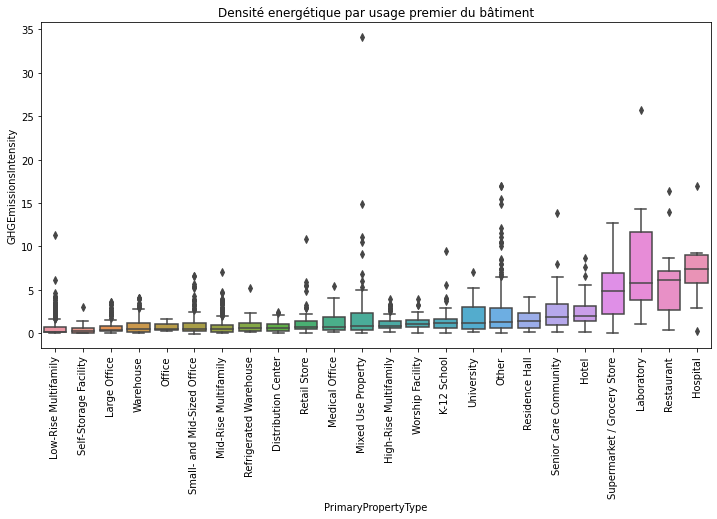

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the medians
medians = data.groupby(['PrimaryPropertyType'])['GHGEmissionsIntensity'].median().sort_values()

# Reorder the dataframe based on the medians
data['PrimaryPropertyType'] = pd.Categorical(data['PrimaryPropertyType'], categories=medians.index, ordered=True)

# Create the boxplot
plt.figure(figsize=(12,6))
sns.boxplot(x='PrimaryPropertyType', y='GHGEmissionsIntensity', data=data)
plt.xticks(rotation=90)
plt.title('Densité energétique par usage premier du bâtiment')
plt.show()


In [8]:
data.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


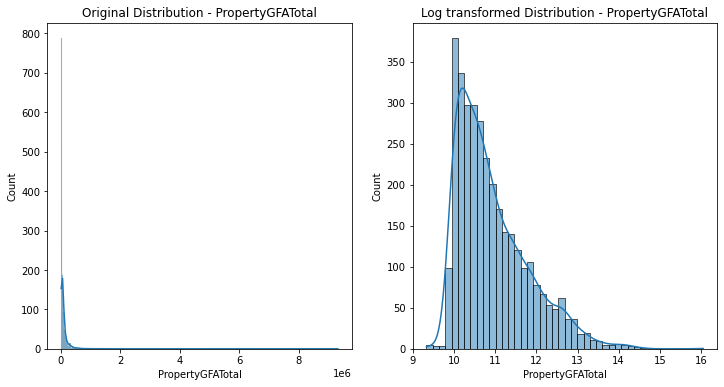

For PropertyGFATotal:
Skewness before log transform: 24.118685092629228
Kurtosis before log transform: 944.8368740187287
Skewness after log transform: 1.1519545318476334
Kurtosis after log transform: 1.2030966824620206
---------------------------


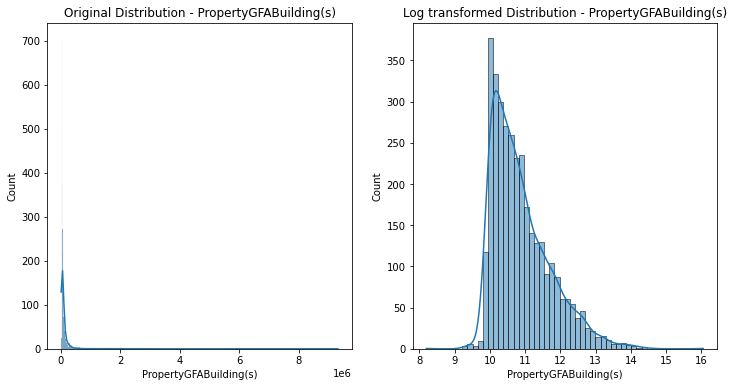

For PropertyGFABuilding(s):
Skewness before log transform: 27.612115250460306
Kurtosis before log transform: 1159.6391830074617
Skewness after log transform: 1.1671169045950425
Kurtosis after log transform: 1.4667604989567264
---------------------------


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

cols_to_transform = ['PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                     'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 
                     'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
                     'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 
                     'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
                     'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 
                     'NaturalGas(kBtu)', 'TotalGHGEmissions', 'GHGEmissionsIntensity']

for col in cols_to_transform:
    if np.issubdtype(data[col].dtype, np.number) and all(data[col]>0):
        fig, ax = plt.subplots(1, 2, figsize=(12, 6))
        
        sns.histplot(data[col], kde=True, ax=ax[0])
        ax[0].set_title('Original Distribution - ' + col)
        
        log_col = np.log1p(data[col])  # Applying log(1+x) transformation
        sns.histplot(log_col, kde=True, ax=ax[1])
        ax[1].set_title('Log transformed Distribution - ' + col)
        
        plt.show()
        
        print(f"For {col}:")
        print(f"Skewness before log transform: {skew(data[col].dropna())}")
        print(f"Kurtosis before log transform: {kurtosis(data[col].dropna())}")
        print(f"Skewness after log transform: {skew(log_col.dropna())}")
        print(f"Kurtosis after log transform: {kurtosis(log_col.dropna())}")
        print("---------------------------")


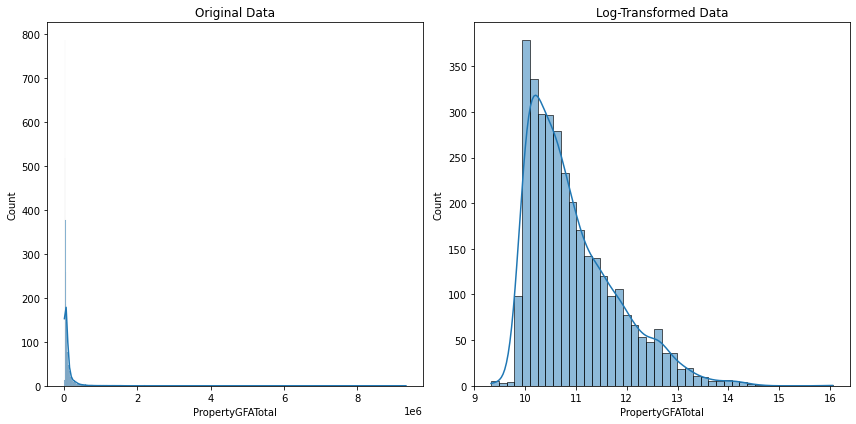

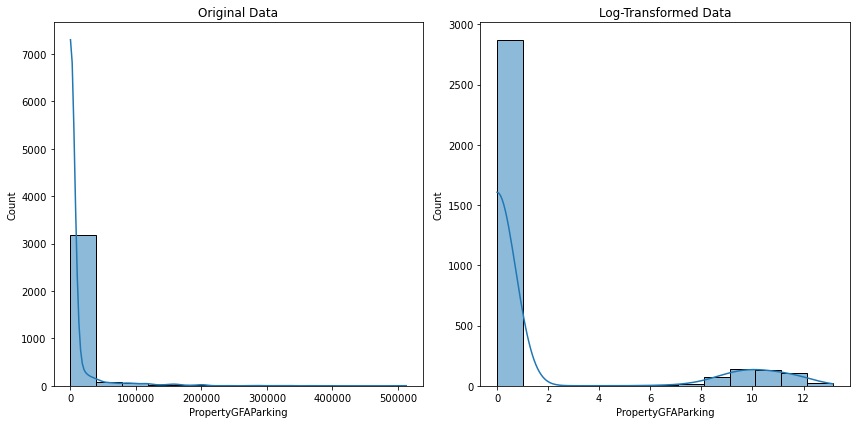

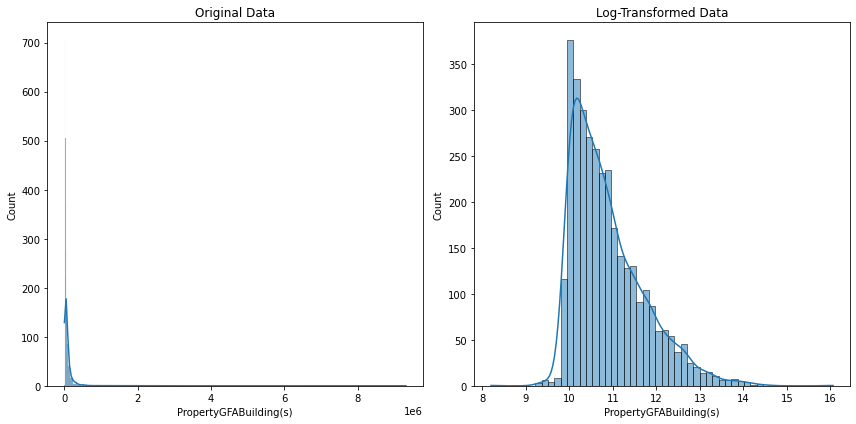

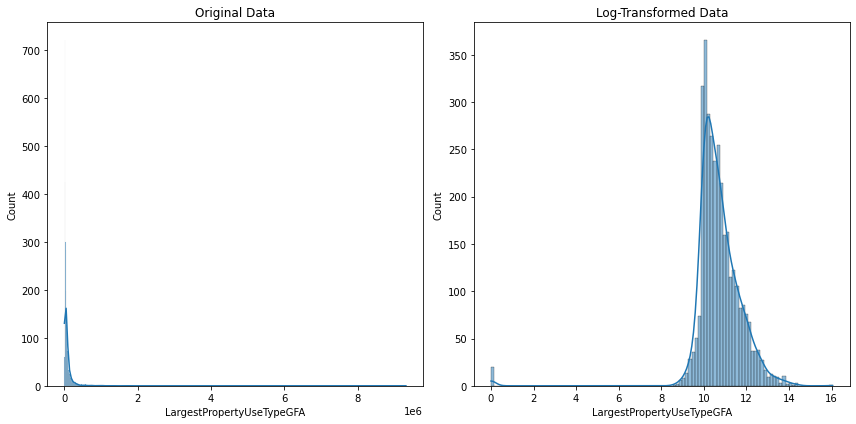

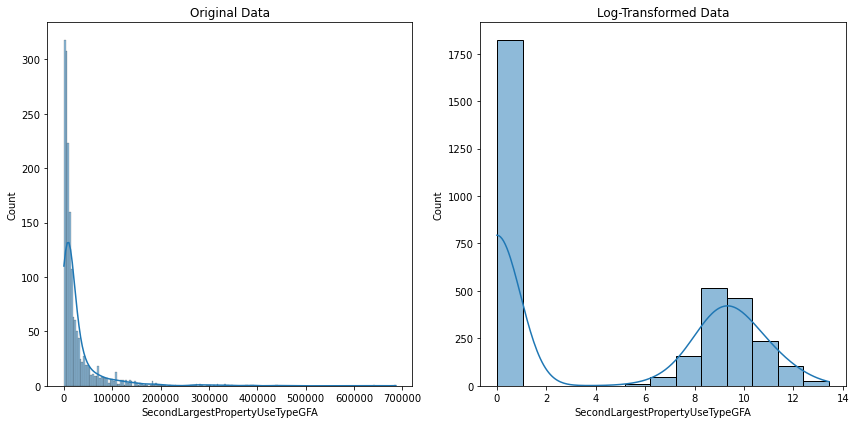

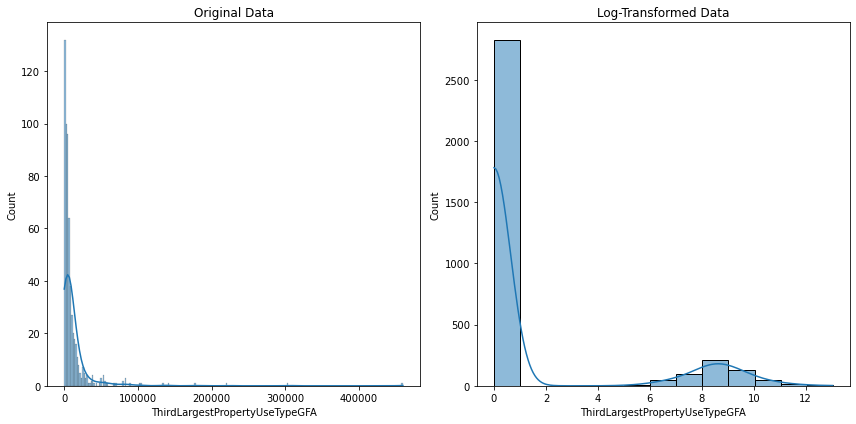

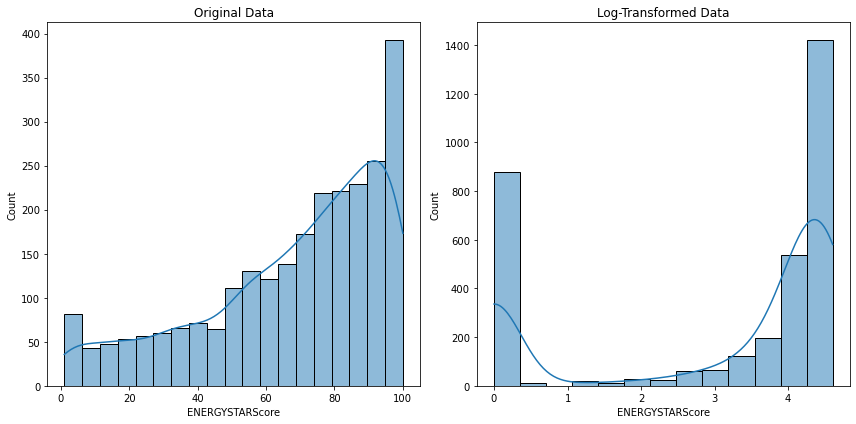

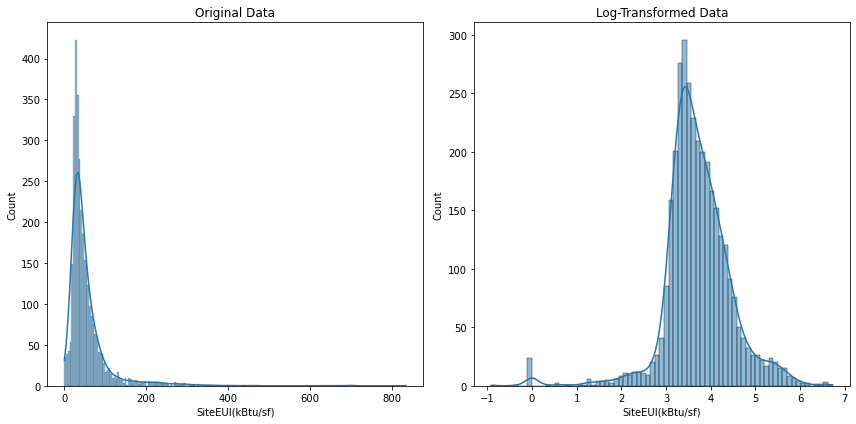

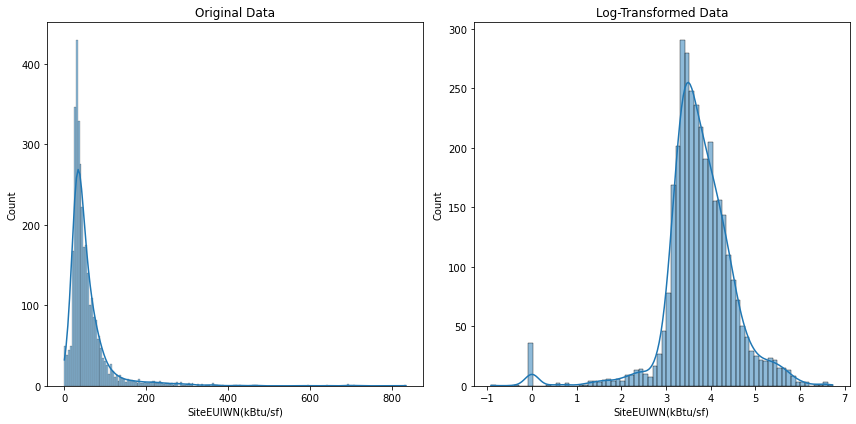

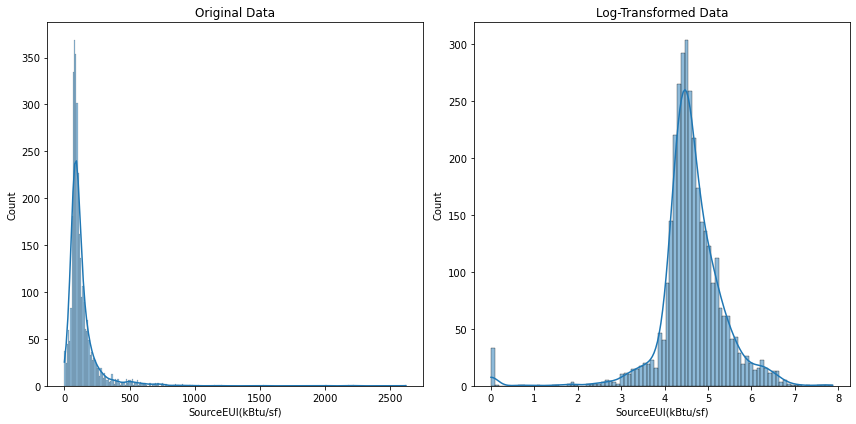

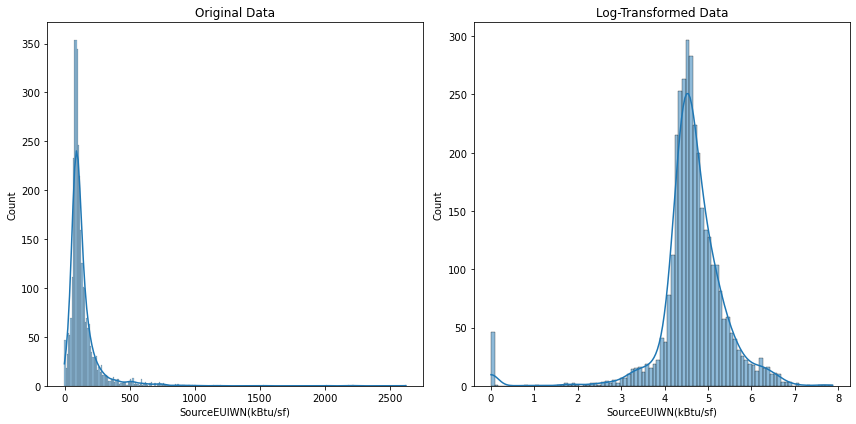

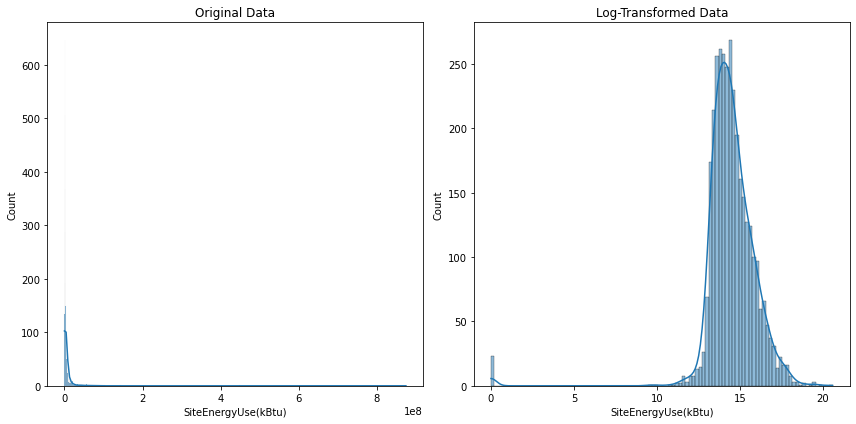

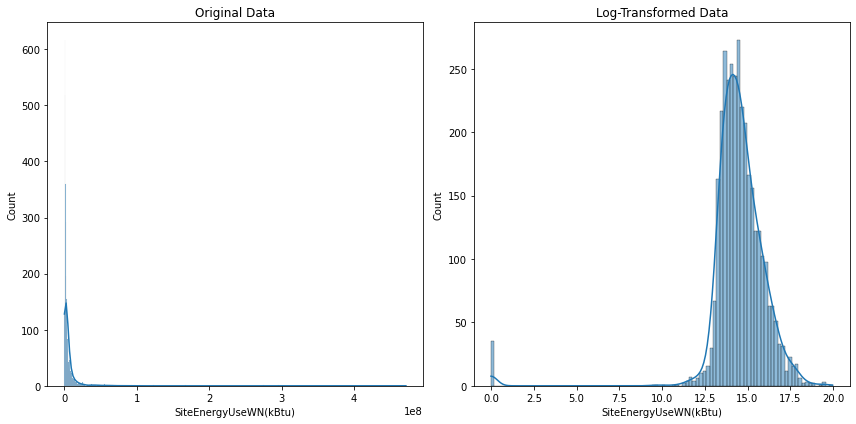

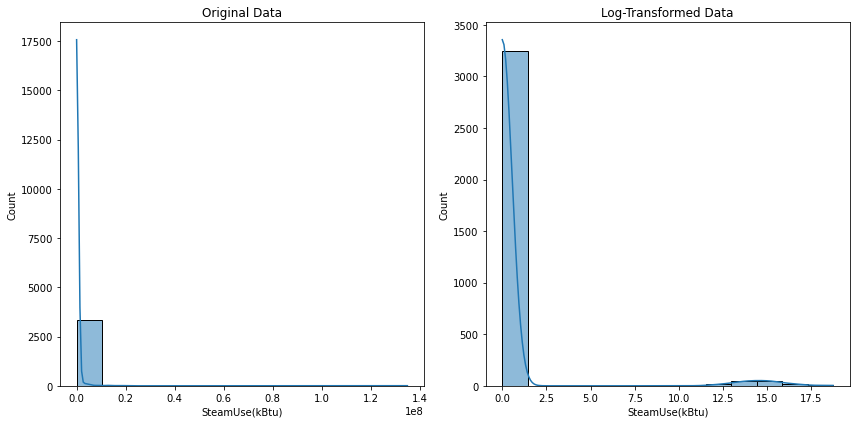

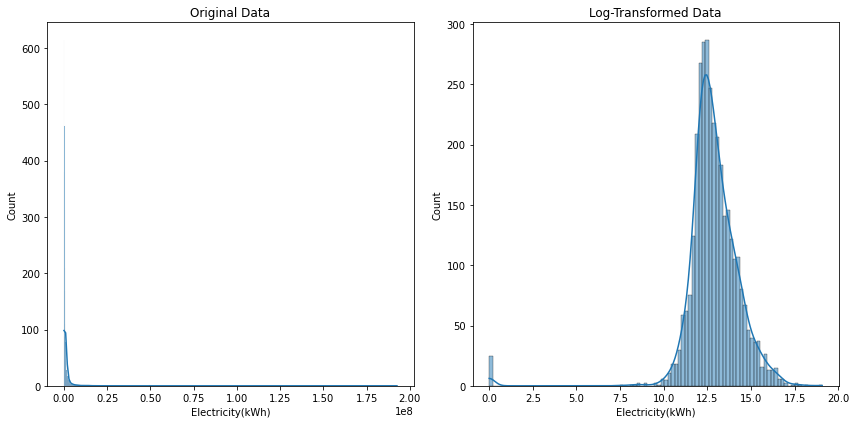

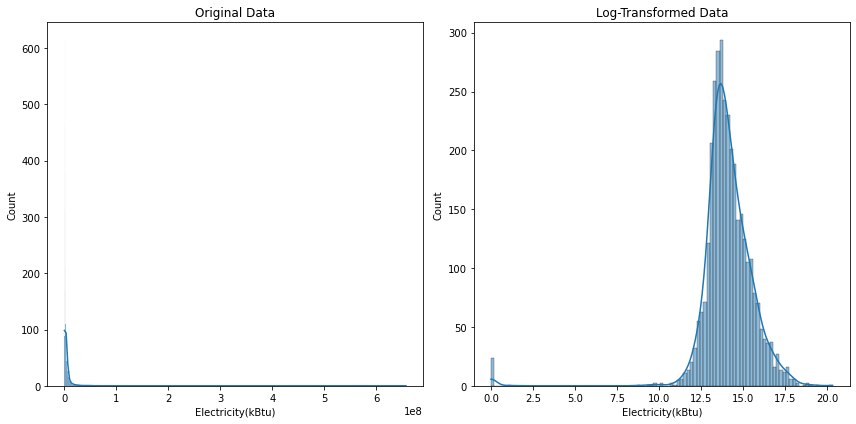

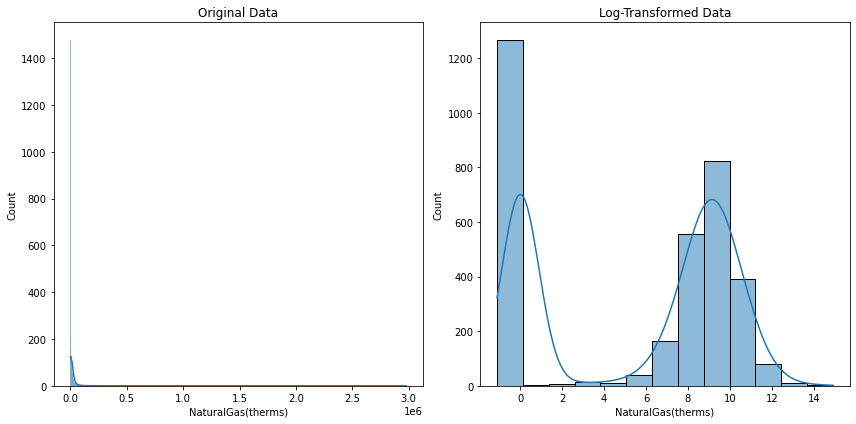

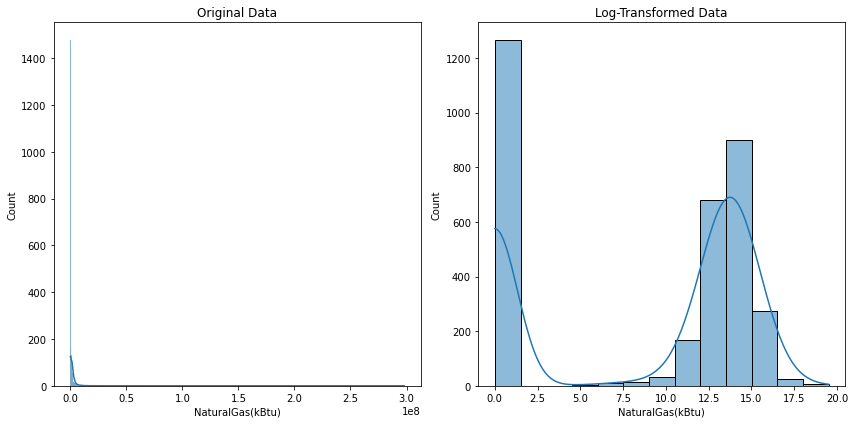

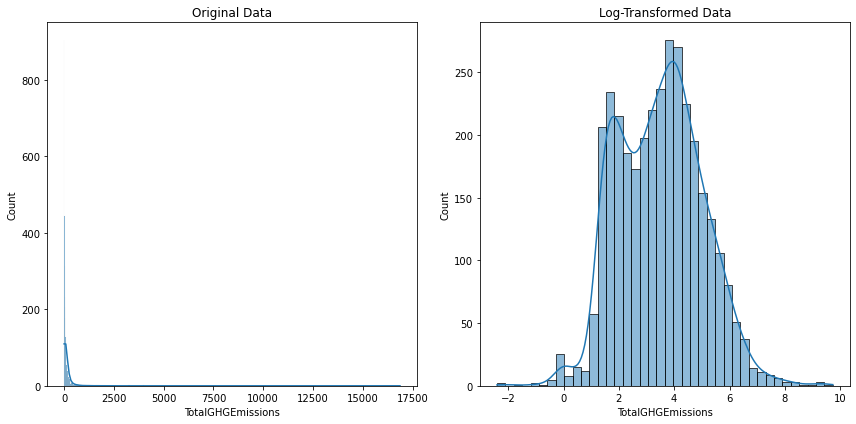

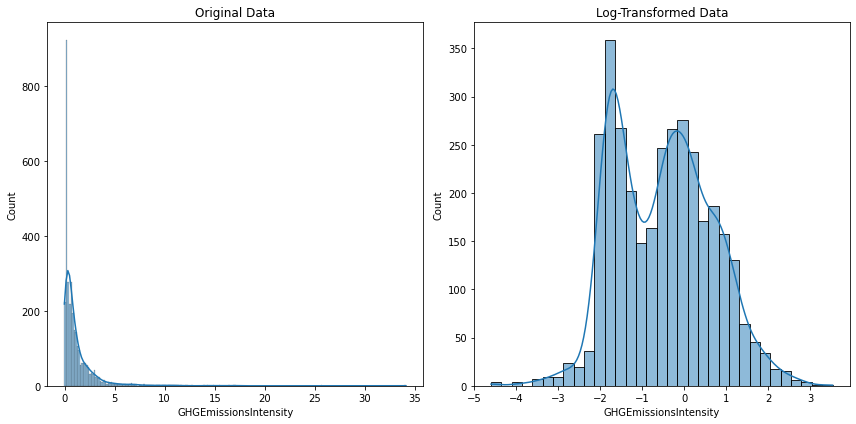

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define a list of columns to transform
cols_to_transform = ['PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 
                     'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 
                     'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)',
                     'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 
                     'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)',
                     'Electricity(kWh)', 'Electricity(kBtu)', 'NaturalGas(therms)', 
                     'NaturalGas(kBtu)', 'TotalGHGEmissions', 'GHGEmissionsIntensity']

# Create a new DataFrame for the transformed data
data_log = data.copy()

# Apply log transformation to the selected columns
for col in cols_to_transform:
    # check if all values are > 0
    if all(data_log[col]>0):
        # Apply the log transformation
        data_log[col] = np.log(data_log[col])
    else:
        # Handle the case where values are <= 0
        data_log[col] = data_log[col].apply(lambda x: np.log(x) if x>0 else 0)

# Create plots before and after transformation
for col in cols_to_transform:
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    
    sns.histplot(data[col], kde=True, ax=ax[0])
    ax[0].set_title('Original Data')
    ax[0].set_xlabel(col)

    sns.histplot(data_log[col], kde=True, ax=ax[1])
    ax[1].set_title('Log-Transformed Data')
    ax[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   OSEBuildingID                    3376 non-null   int64   
 1   DataYear                         3376 non-null   int64   
 2   BuildingType                     3376 non-null   object  
 3   PrimaryPropertyType              3376 non-null   category
 4   PropertyName                     3376 non-null   object  
 5   Address                          3376 non-null   object  
 6   City                             3376 non-null   object  
 7   State                            3376 non-null   object  
 8   ZipCode                          3360 non-null   float64 
 9   TaxParcelIdentificationNumber    3376 non-null   object  
 10  CouncilDistrictCode              3376 non-null   int64   
 11  Neighborhood                     3376 non-null   object  
 12  Latitu

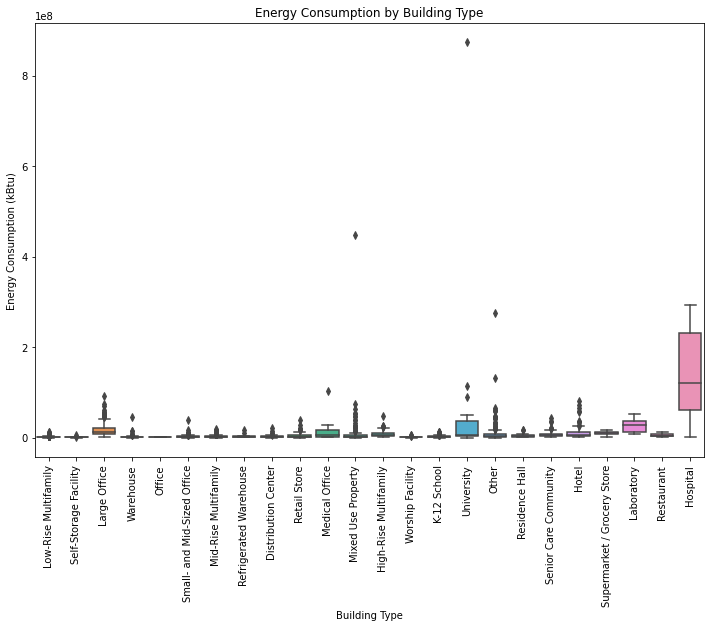

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assume you've loaded your data into a DataFrame named df
# df = pd.read_csv('your_dataset.csv') 

plt.figure(figsize=(12, 8))
sns.boxplot(x='PrimaryPropertyType', y='SiteEnergyUse(kBtu)', data=data)

plt.xticks(rotation=90)  # Rotate the x-labels for readability
plt.title('Energy Consumption by Building Type')
plt.xlabel('Building Type')
plt.ylabel('Energy Consumption (kBtu)')
plt.show()


In [16]:

# Calculate energy consumption per square meter
data['EnergyUsePerSqM'] = data['GHGEmissionsIntensity'] / data['PropertyGFATotal']


In [14]:
missing_values = data.isnull().sum()
total_values = np.product(data.shape)
missing_percent = (missing_values.sum()/total_values) * 100

print(f'Le taux de valeurs manquantes dans le dataset est: {missing_percent}%')


Le taux de valeurs manquantes dans le dataset est: 12.847723057902327%


## contenu du dataset

In [17]:
data.shape

(3376, 47)

In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   OSEBuildingID                    3376 non-null   int64   
 1   DataYear                         3376 non-null   int64   
 2   BuildingType                     3376 non-null   object  
 3   PrimaryPropertyType              3376 non-null   category
 4   PropertyName                     3376 non-null   object  
 5   Address                          3376 non-null   object  
 6   City                             3376 non-null   object  
 7   State                            3376 non-null   object  
 8   ZipCode                          3360 non-null   float64 
 9   TaxParcelIdentificationNumber    3376 non-null   object  
 10  CouncilDistrictCode              3376 non-null   int64   
 11  Neighborhood                     3376 non-null   object  
 12  Latitu

In [21]:
def qualitative_data(data):
    qualitative_cols = [col for col in data.columns if data[col].dtype == object]
    new_data = pd.DataFrame(index=qualitative_cols, columns=['Unique Values Count', 'Values'])

    for col in qualitative_cols:
        unique_vals = data[col].unique()
        unique_vals_count = len(unique_vals)
        vals_str = ', '.join([str(val) for val in unique_vals])
        new_data.loc[col] = [unique_vals_count, vals_str]

    return new_data


In [23]:
df_qualitative_data = qualitative_data(data)
df_qualitative_data

,Unique Values Count,Values
BuildingType,8,"NonResidential, Nonresidential COS, Multifamil..."
PropertyName,3362,"Mayflower park hotel, Paramount Hotel, 5673-Th..."
Address,3354,"405 Olive way, 724 Pine street, 1900 5th Avenu..."
City,1,Seattle
State,1,WA
TaxParcelIdentificationNumber,3268,"0659000030, 0659000220, 0659000475, 0659000640..."
Neighborhood,19,"DOWNTOWN, SOUTHEAST, NORTHEAST, EAST, Central,..."
ListOfAllPropertyUseTypes,467,"Hotel, Hotel, Parking, Restaurant, Hotel, Park..."
LargestPropertyUseType,57,"Hotel, Police Station, Other - Entertainment/P..."
SecondLargestPropertyUseType,51,"nan, Parking, Office, Restaurant, K-12 School,..."


### valeurs differentes prise pour chaque colonne à données qualitatives

In [24]:
qualitative_cols = data.select_dtypes(include='object').columns.tolist()

for col in qualitative_cols:
    unique_values = data[col].unique()
    print("\n",col, ": valeurs uniques", len(unique_values),"\n", unique_values)


 BuildingType : valeurs uniques 8 
 ['NonResidential' 'Nonresidential COS' 'Multifamily MR (5-9)'
 'SPS-District K-12' 'Campus' 'Multifamily LR (1-4)'
 'Multifamily HR (10+)' 'Nonresidential WA']

 PropertyName : valeurs uniques 3362 
 ['Mayflower park hotel' 'Paramount Hotel' '5673-The Westin Seattle' ...
 'Queen Anne Pool' 'South Park Community Center'
 'Van Asselt Community Center']

 Address : valeurs uniques 3354 
 ['405 Olive way' '724 Pine street' '1900 5th Avenue' ... '1920 1st Ave W'
 '8319 8th Ave S' '2820 S Myrtle St']

 City : valeurs uniques 1 
 ['Seattle']

 State : valeurs uniques 1 
 ['WA']

 TaxParcelIdentificationNumber : valeurs uniques 3268 
 ['0659000030' '0659000220' '0659000475' ... '1624049080' '7883603155'
 '7857002030']

 Neighborhood : valeurs uniques 19 
 ['DOWNTOWN' 'SOUTHEAST' 'NORTHEAST' 'EAST' 'Central' 'NORTH'
 'MAGNOLIA / QUEEN ANNE' 'LAKE UNION' 'GREATER DUWAMISH' 'BALLARD'
 'NORTHWEST' 'CENTRAL' 'SOUTHWEST' 'DELRIDGE' 'Ballard' 'North' 'Delridge'
 '

In [25]:
data.dtypes.value_counts()

float64     23
object      14
int64        8
category     1
bool         1
dtype: int64

In [26]:
data.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,0.000032
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,0.000028
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19,0.000002
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67,0.000076
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88,0.000016


## statistiques descriptives des données numériques

In [27]:
data.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,3376.000000,3.376000e+03,3.356000e+03,1679.000000,596.000000,2533.000000,3369.000000,3370.000000,3367.000000,3367.000000,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000,3.367000e+03
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,8001.526066,8.683201e+04,7.917764e+04,28444.075817,11738.675166,67.918674,54.732116,57.033798,134.232848,137.783932,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916,2.806630e-05
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,32326.723928,2.079398e+05,2.017034e+05,54392.917928,29331.199286,26.873271,56.273124,57.163330,139.287554,139.109807,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452,5.870513e-05
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-2.100000,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000,-3.846154e-07
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,0.000000,2.775600e+04,2.509475e+04,5000.000000,2239.000000,53.000000,27.900000,29.400000,74.699997,78.400002,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000,4.153489e-06
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,0.000000,4.321600e+04,3.989400e+04,10664.000000,5043.000000,75.000000,38.599998,40.900002,96.199997,101.099998,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000,9.025853e-06
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,0.000000,8.427625e+04,7.620025e+04,26640.000000,10138.750000,90.000000,60.400002,64.275002,143.899994,148.349998,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000,2.887467e-05
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,686750.000000,459748.000000,100.000000,834.400024,834.400024,2620.000000,2620.000000,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000,1.325867e-03


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> On observe déjà quelques valeurs aberrantes comme des valeurs negatives là où il est mensuré les émissions, cela nous servira plus tard dans le nettoyage de données <br>
Comments,  est à 0 ou à NaN est est considéré comme une valeur numerique alors que c'en n'est pas une<br>
ZipCode, Latitude et Longitude à retirer des valeurs num</p>

## Choix des colonnes potentiellement utile pour le projet

### valeurs manquantes et taux completion

In [28]:
missing_values = data.isnull().sum()
total_values = np.product(data.shape)
missing_percent = (missing_values.sum()/total_values) * 100

print(f'Le taux de valeurs manquantes dans le dataset est: {missing_percent}%')


Le taux de valeurs manquantes dans le dataset est: 12.580039326409196%


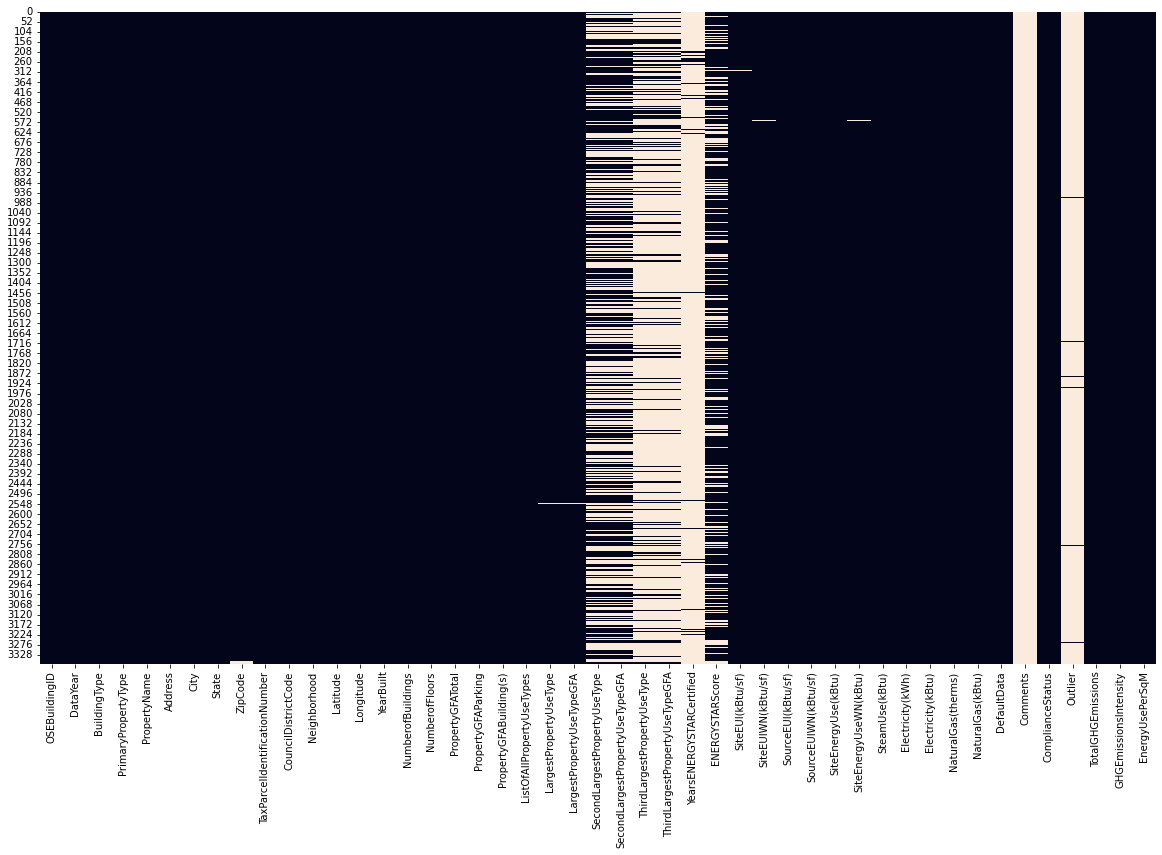

In [29]:
plt.figure(figsize=(20,12))
sns.heatmap(data.isna(), cbar= False)
plt.show()

In [30]:
def valeurs_manquantes(df):
  missing_df = df.isnull().sum(axis=0).reset_index()
  missing_df.columns = ['column_name', 'nombre valeurs manquantes']
  missing_df['taux de remplissage'] = (df.shape[0]-missing_df['nombre valeurs manquantes'])/df.shape[0]*100
  missing_df = missing_df.sort_values('taux de remplissage').reset_index(drop = True)
  return missing_df

In [31]:
valeurs_manquantes(data)

,column_name,nombre valeurs manquantes,taux de remplissage
0,Comments,3376,0.000000
1,Outlier,3344,0.947867
2,YearsENERGYSTARCertified,3257,3.524882
3,ThirdLargestPropertyUseType,2780,17.654028
4,ThirdLargestPropertyUseTypeGFA,2780,17.654028
5,SecondLargestPropertyUseType,1697,49.733412
6,SecondLargestPropertyUseTypeGFA,1697,49.733412
7,ENERGYSTARScore,843,75.029621
8,LargestPropertyUseTypeGFA,20,99.407583
9,LargestPropertyUseType,20,99.407583


In [32]:
data.duplicated().sum()

0

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> Pas de doublons dans le dataset
        </p>

In [33]:
print("nombre de valeurs uniques pour chaque colonne :\n")
for col in data.columns:
    print(col + ' : ' + str(data[col].nunique()))

nombre de valeurs uniques pour chaque colonne :

OSEBuildingID : 3376
DataYear : 1
BuildingType : 8
PrimaryPropertyType : 24
PropertyName : 3362
Address : 3354
City : 1
State : 1
ZipCode : 55
TaxParcelIdentificationNumber : 3268
CouncilDistrictCode : 7
Neighborhood : 19
Latitude : 2876
Longitude : 2656
YearBuilt : 113
NumberofBuildings : 17
NumberofFloors : 50
PropertyGFATotal : 3195
PropertyGFAParking : 496
PropertyGFABuilding(s) : 3193
ListOfAllPropertyUseTypes : 466
LargestPropertyUseType : 56
LargestPropertyUseTypeGFA : 3122
SecondLargestPropertyUseType : 50
SecondLargestPropertyUseTypeGFA : 1352
ThirdLargestPropertyUseType : 44
ThirdLargestPropertyUseTypeGFA : 501
YearsENERGYSTARCertified : 65
ENERGYSTARScore : 100
SiteEUI(kBtu/sf) : 1085
SiteEUIWN(kBtu/sf) : 1105
SourceEUI(kBtu/sf) : 1648
SourceEUIWN(kBtu/sf) : 1694
SiteEnergyUse(kBtu) : 3354
SiteEnergyUseWN(kBtu) : 3341
SteamUse(kBtu) : 131
Electricity(kWh) : 3352
Electricity(kBtu) : 3351
NaturalGas(therms) : 2109
NaturalGas(kBt

In [34]:
num_columns = list(data.select_dtypes(include=['float64', 'int64']).columns)
print("Les variables numériques sont les suivantes : \n")
for num in num_columns :
    print(num)

Les variables numériques sont les suivantes : 

OSEBuildingID
DataYear
ZipCode
CouncilDistrictCode
Latitude
Longitude
YearBuilt
NumberofBuildings
NumberofFloors
PropertyGFATotal
PropertyGFAParking
PropertyGFABuilding(s)
LargestPropertyUseTypeGFA
SecondLargestPropertyUseTypeGFA
ThirdLargestPropertyUseTypeGFA
ENERGYSTARScore
SiteEUI(kBtu/sf)
SiteEUIWN(kBtu/sf)
SourceEUI(kBtu/sf)
SourceEUIWN(kBtu/sf)
SiteEnergyUse(kBtu)
SiteEnergyUseWN(kBtu)
SteamUse(kBtu)
Electricity(kWh)
Electricity(kBtu)
NaturalGas(therms)
NaturalGas(kBtu)
Comments
TotalGHGEmissions
GHGEmissionsIntensity
EnergyUsePerSqM


In [35]:
data[num_columns].head(2)

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,98101.0,7,47.61220,-122.33799,1927,1.0,12,88434,0,88434,88434.0,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.0,1.156514e+06,3946027.0,12764.52930,1276453.0,NaN,249.98,2.83,0.000032
1,2,2016,98101.0,7,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,83880.0,15064.0,4622.0,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.0,9.504252e+05,3242851.0,51450.81641,5145082.0,NaN,295.86,2.86,0.000028


In [36]:
data[num_columns].dtypes

OSEBuildingID                        int64
DataYear                             int64
ZipCode                            float64
CouncilDistrictCode                  int64
Latitude                           float64
Longitude                          float64
YearBuilt                            int64
NumberofBuildings                  float64
NumberofFloors                       int64
PropertyGFATotal                     int64
PropertyGFAParking                   int64
PropertyGFABuilding(s)               int64
LargestPropertyUseTypeGFA          float64
SecondLargestPropertyUseTypeGFA    float64
ThirdLargestPropertyUseTypeGFA     float64
ENERGYSTARScore                    float64
SiteEUI(kBtu/sf)                   float64
SiteEUIWN(kBtu/sf)                 float64
SourceEUI(kBtu/sf)                 float64
SourceEUIWN(kBtu/sf)               float64
SiteEnergyUse(kBtu)                float64
SiteEnergyUseWN(kBtu)              float64
SteamUse(kBtu)                     float64
Electricity

In [37]:
qualitative_cols = [col for col in data.columns if data[col].dtype == object]
print("Les variables qualitatives sont les suivantes : \n")
for qual in qualitative_cols :
    print(qual)

Les variables qualitatives sont les suivantes : 

BuildingType
PropertyName
Address
City
State
TaxParcelIdentificationNumber
Neighborhood
ListOfAllPropertyUseTypes
LargestPropertyUseType
SecondLargestPropertyUseType
ThirdLargestPropertyUseType
YearsENERGYSTARCertified
ComplianceStatus
Outlier


In [38]:
data[qualitative_cols].head(2)

,BuildingType,PropertyName,Address,City,State,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,YearsENERGYSTARCertified,ComplianceStatus,Outlier
0,NonResidential,Mayflower park hotel,405 Olive way,Seattle,WA,0659000030,DOWNTOWN,Hotel,Hotel,NaN,NaN,NaN,Compliant,NaN
1,NonResidential,Paramount Hotel,724 Pine street,Seattle,WA,0659000220,DOWNTOWN,"Hotel, Parking, Restaurant",Hotel,Parking,Restaurant,NaN,Compliant,NaN


/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_37975/3835081077.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Blues")


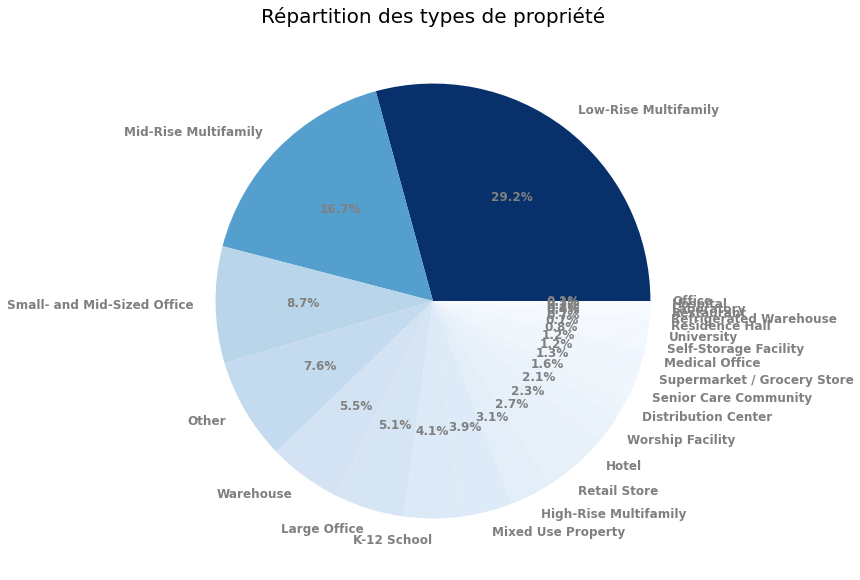

In [39]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Obtenir la répartition des valeurs dans la colonne "PrimaryPropertyType"
property_type_counts = data['PrimaryPropertyType'].value_counts()

# Normaliser les comptes pour créer une échelle entre 0 et 1
norm = plt.Normalize(property_type_counts.min(), property_type_counts.max())

# Créer une colormap
cmap = cm.get_cmap("Blues")

# Créer le camembert, en utilisant les couleurs de la colormap
plt.figure(figsize=(10,10))
plt.pie(property_type_counts, labels = property_type_counts.index, 
        autopct='%1.1f%%', colors=cmap(norm(property_type_counts.values)), 
        textprops={'color':'#808080', 'weight':'bold', 'fontsize':12})
plt.title('Répartition des types de propriété', fontsize=20)
plt.show()

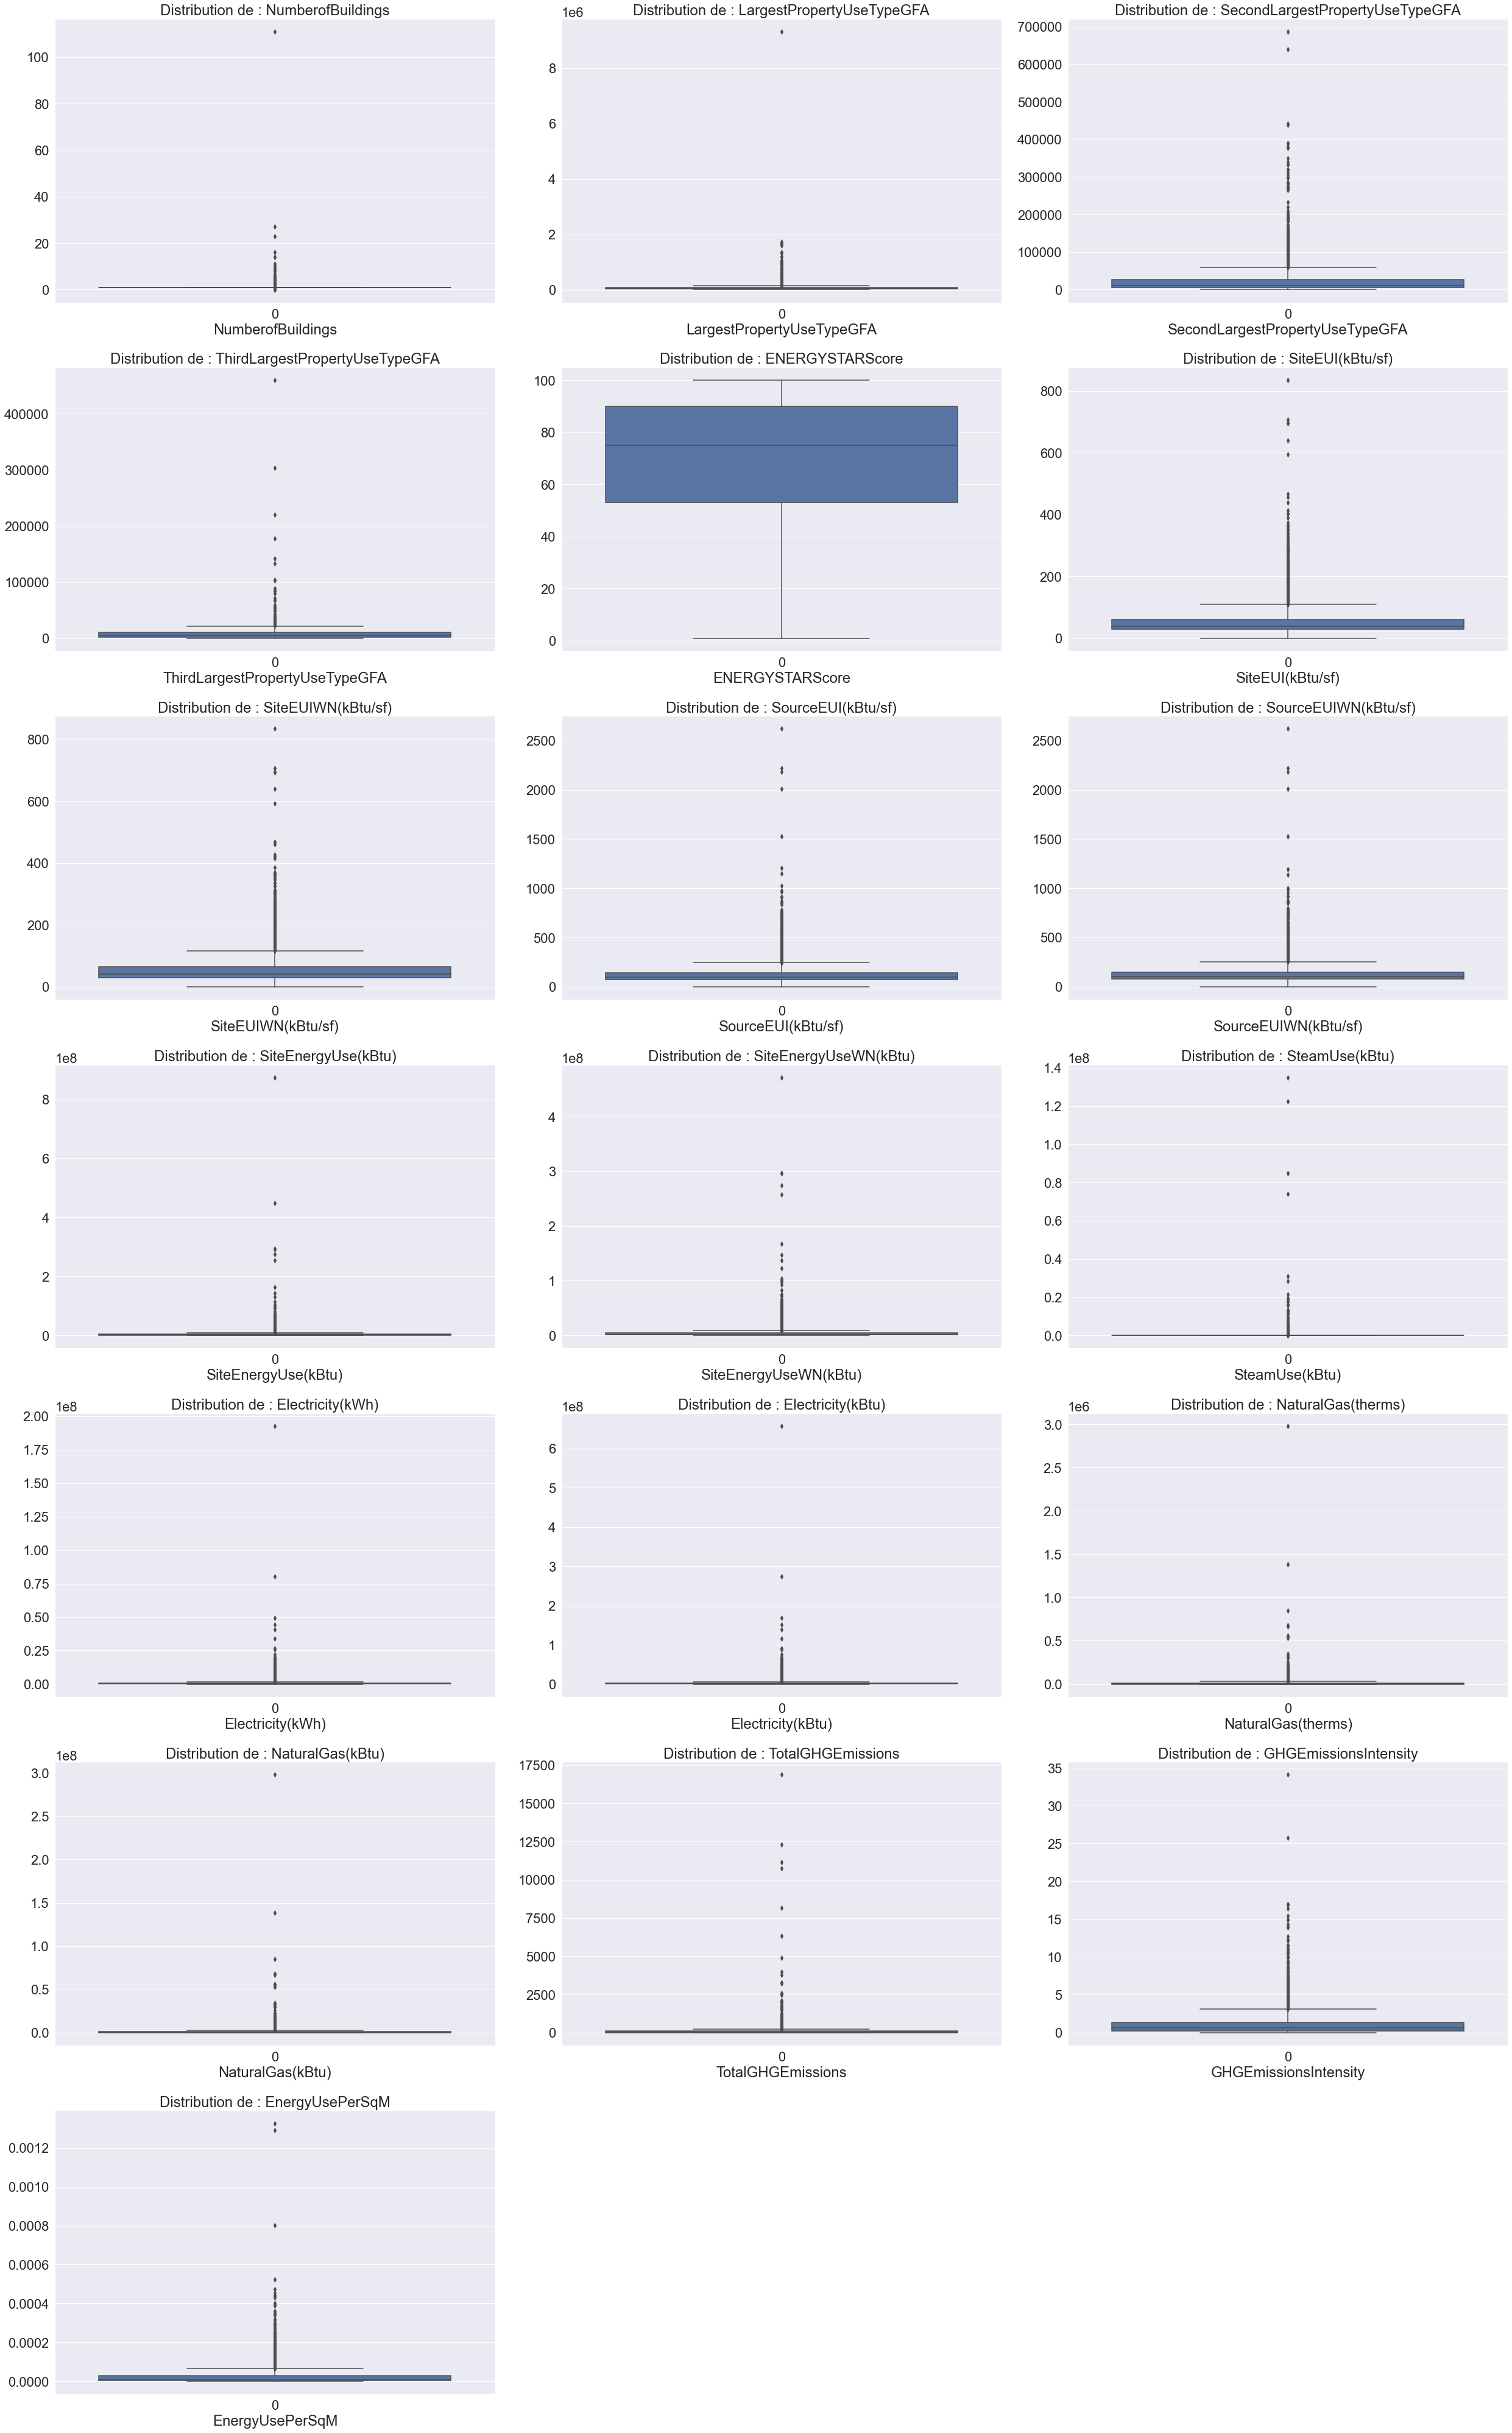

In [40]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_columns = data.select_dtypes(include=['int32', 'float64']).columns
numeric_columns = numeric_columns.drop(['ZipCode', 'Longitude', 'Latitude', 'Comments'])

sns.set(font_scale=2)


n = len(numeric_columns)
ncols = 3
nrows = n // ncols + (n % ncols > 0)


fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))

for idx, column in enumerate(numeric_columns):
    row, col = idx // ncols, idx % ncols
    sns.boxplot(data[column], ax=axes[row, col])
    chaine = 'Distribution de : ' + column
    axes[row, col].set_title(chaine)
    axes[row, col].set_xlabel(column)


for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row, col])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


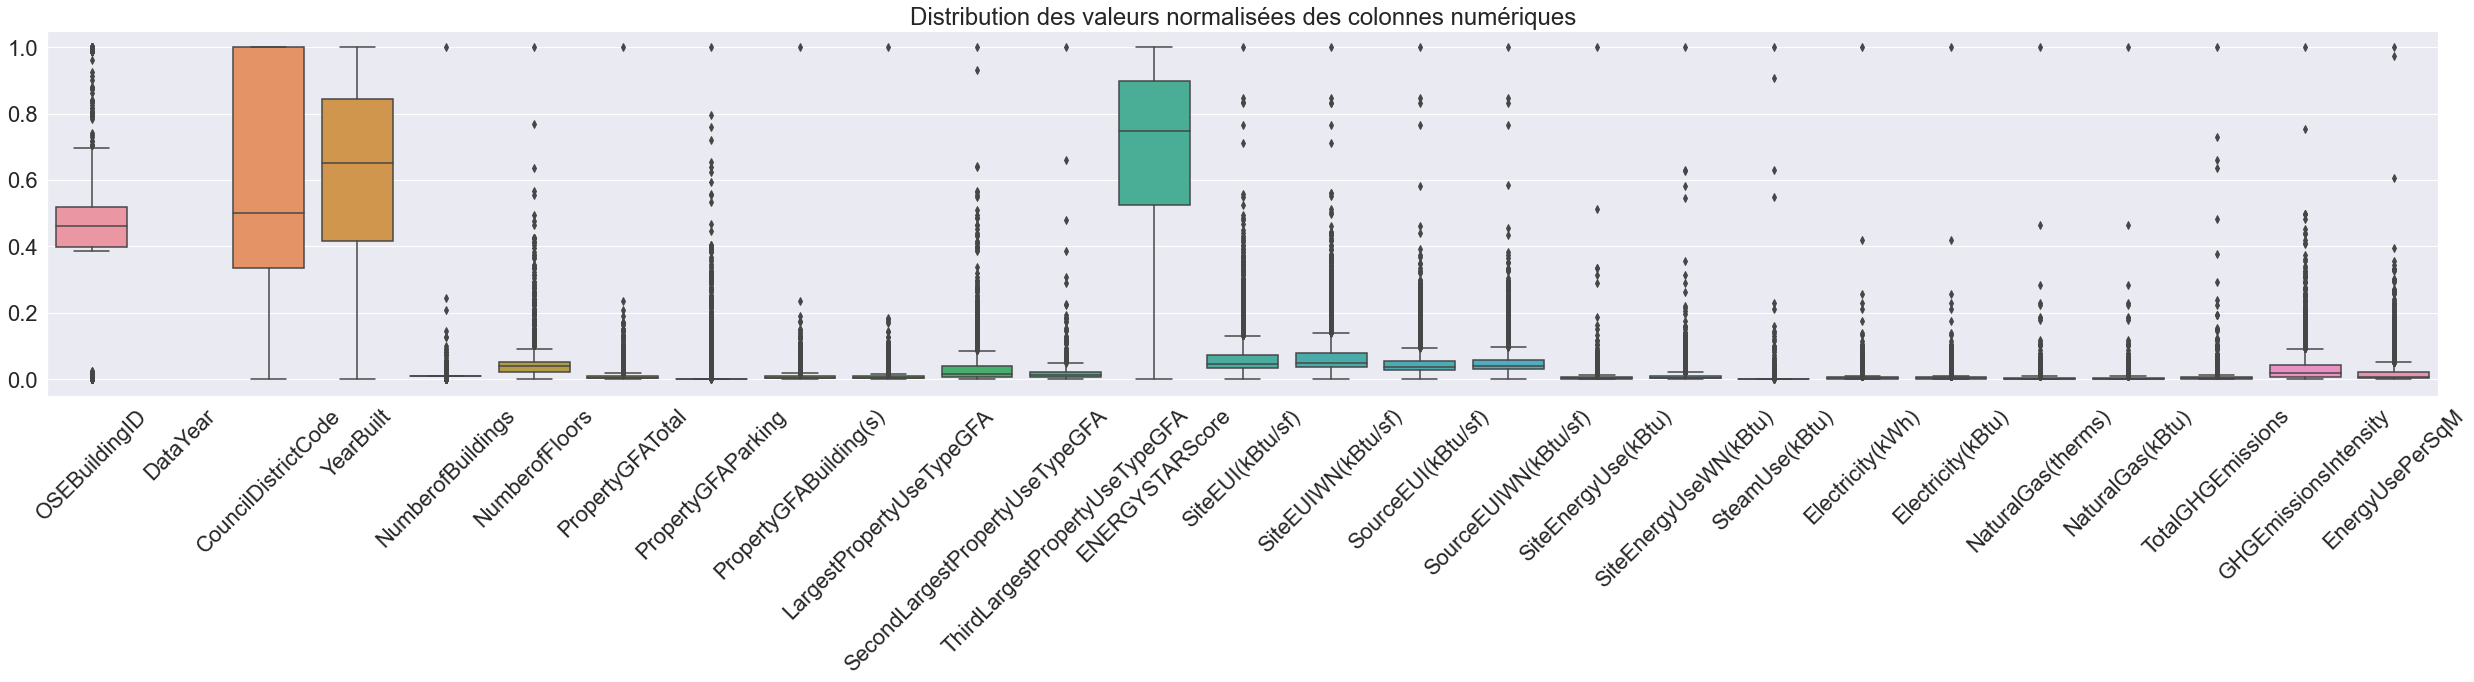

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns
numeric_columns = data.select_dtypes(include=['int64', 'float64']).columns
numeric_columns = numeric_columns.drop(['ZipCode', 'Longitude', 'Latitude', 'Comments'])

# Normalize the numeric columns
normalized_data = data[numeric_columns].apply(lambda x: (x - x.min()) / (x.max() - x.min()))

sns.set(font_scale=2)

# Set the figure size
fig, ax = plt.subplots(figsize=(35, 10))

# Create a boxplot for the normalized data
sns.boxplot(data=normalized_data, ax=ax)

# Set the title and labels
ax.set_title('Distribution des valeurs normalisées des colonnes numériques')
ax.set_xticklabels(numeric_columns, rotation=45)

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> On voit que ThirdLargest property a des valeurs significativement plus élevées que SecondLargestProperty et LargestPropertyUseTypeGFA
</p> 

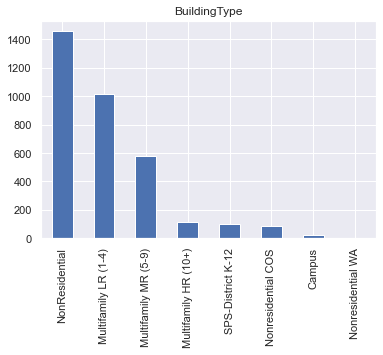

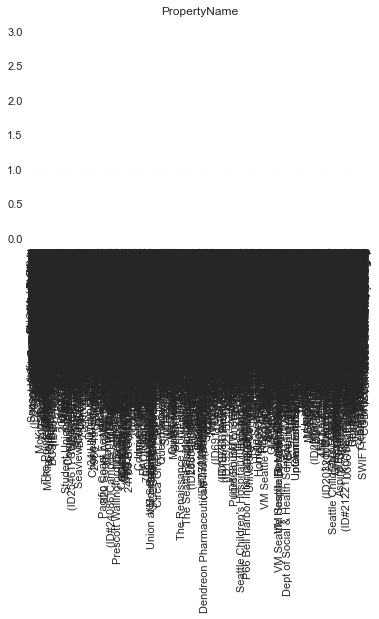

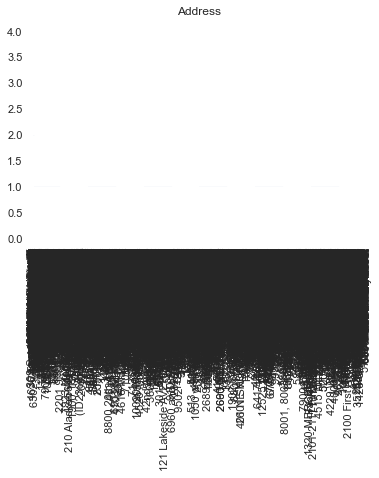

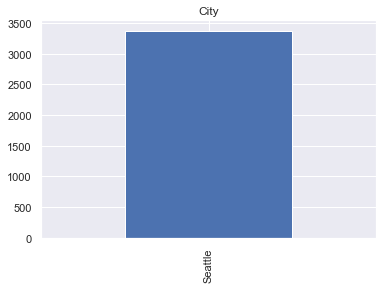

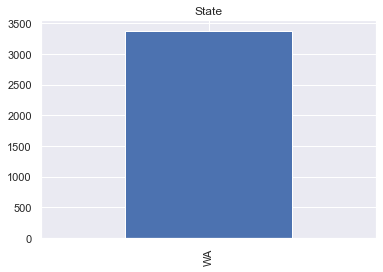

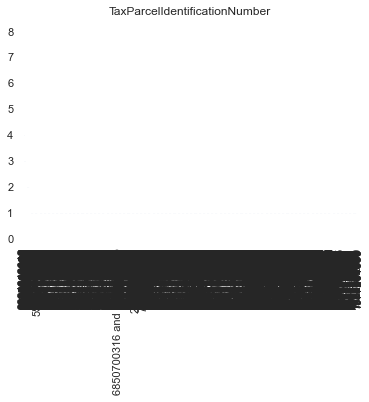

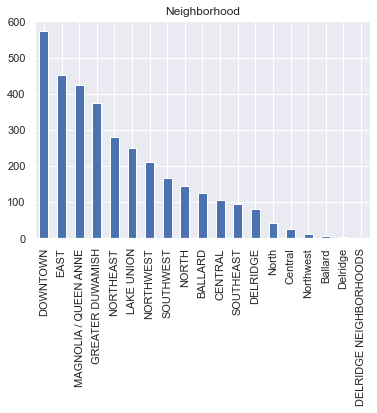

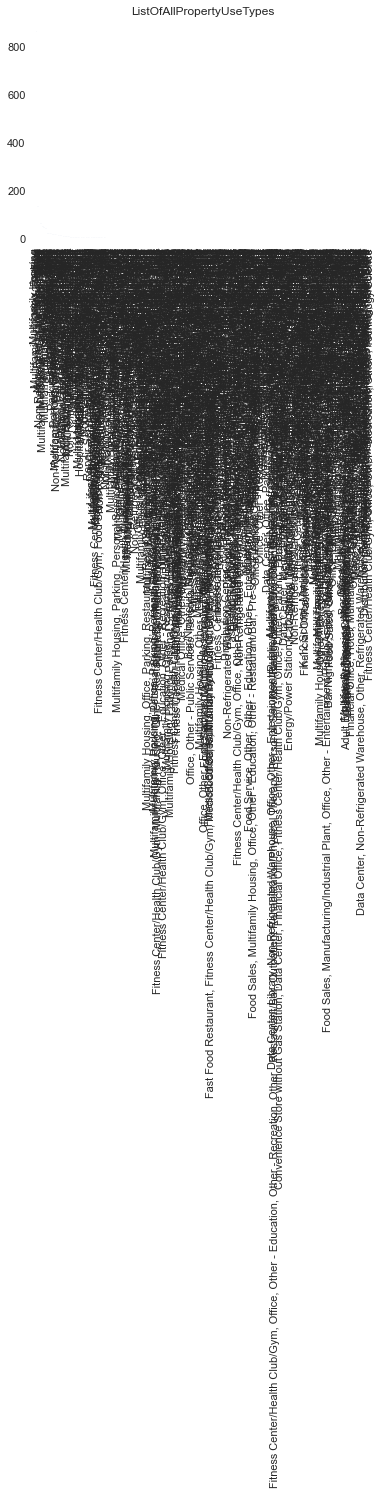

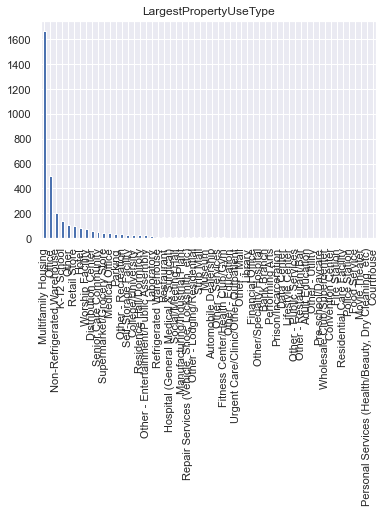

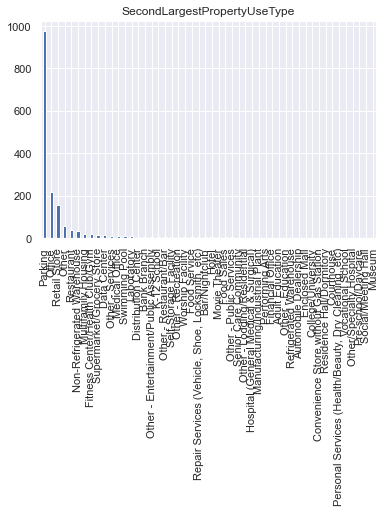

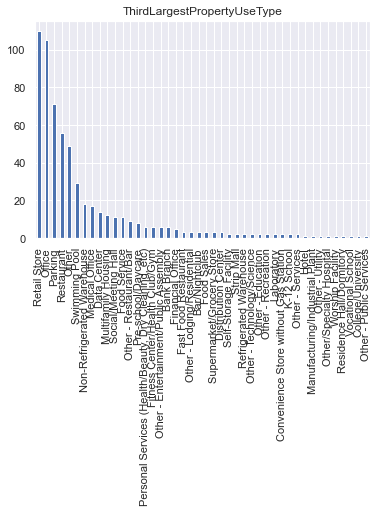

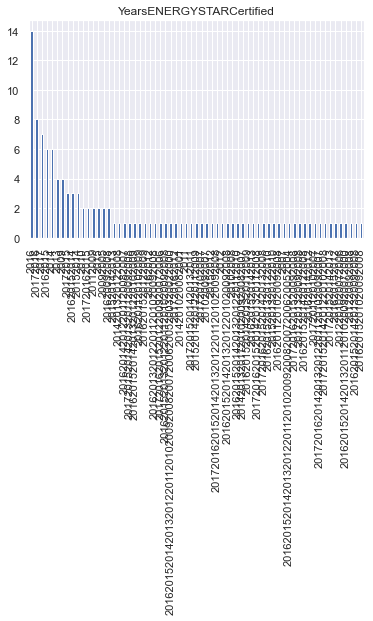

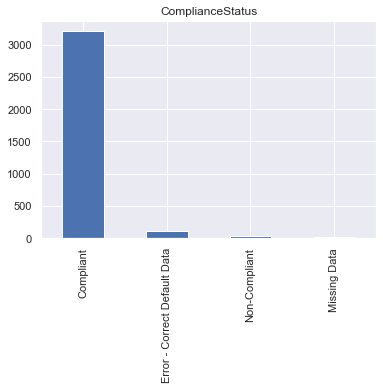

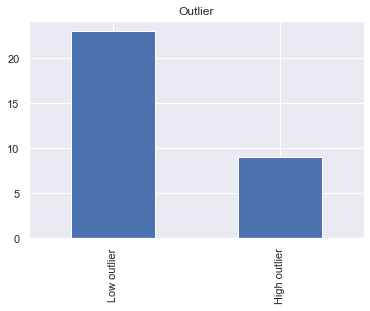

In [42]:
# Pour chaque colonne catégorielle
for column in data.select_dtypes(include=['object']).columns:
    # Créer un diagramme en barres
    plt.figure()
    data[column].value_counts().plot(kind='bar')
    plt.title(column)


/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_37975/1066875183.py:7: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  mask = np.zeros_like(corr, dtype=np.bool)


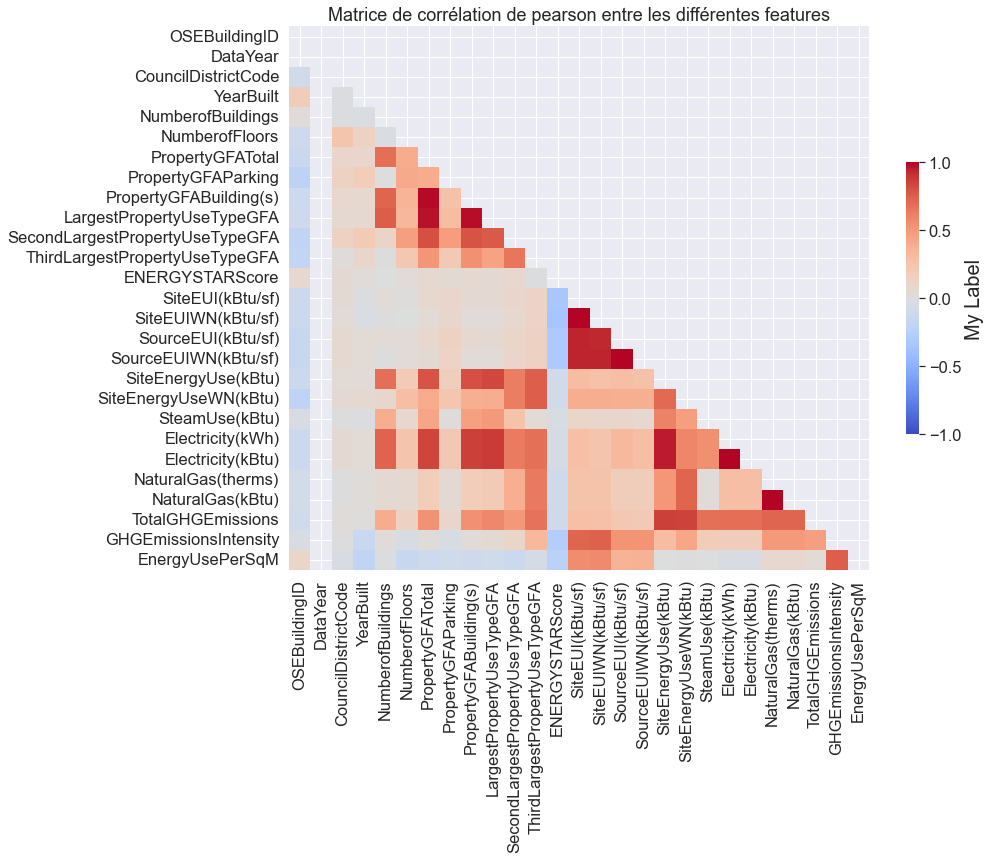

In [43]:
plt.figure(figsize=(13,10))
sns.set(font_scale=1.5)  # Augmente la taille des labels sur l'axe des y et x
plt.title('Matrice de corrélation de pearson entre les différentes features')

corr = data[numeric_columns].corr()

mask = np.zeros_like(corr, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True 

ax = sns.heatmap(corr, mask=mask, vmin=-1, cmap='coolwarm', cbar_kws={"shrink": .5, 'label': 'My Label', 'orientation': 'vertical'})
ax.figure.axes[-1].yaxis.label.set_size(20)  # Modifie la taille de la légende de la colorbar

plt.show()


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> <br>• on voit que les valeurs "WN" sont des doublons <br> • que Largest propertFGA est fortement lié aux variables liés aux valeurs cibles d'emission de co2 et de consommation d'energie<br>
</p> 

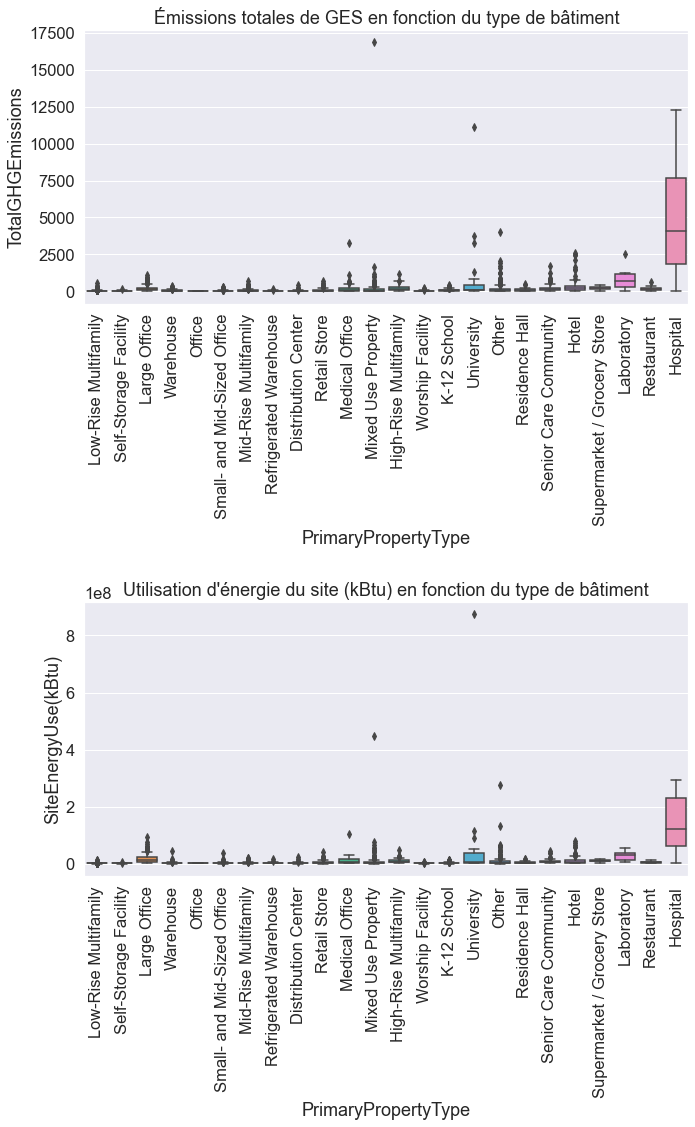

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ajuster la taille de la figure
fig, axs = plt.subplots(2, 1, figsize=(10,16))

# Créer un graphique en boîte (boxplot) pour "TotalGHGEmissions"
sns.boxplot(x="PrimaryPropertyType", y="TotalGHGEmissions", data=data, ax=axs[0])
axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=90)
axs[0].set_title("Émissions totales de GES en fonction du type de bâtiment")

# Créer un graphique en boîte (boxplot) pour "SiteEnergyUse(kBtu)"
sns.boxplot(x="PrimaryPropertyType", y="SiteEnergyUse(kBtu)", data=data, ax=axs[1])
axs[1].set_xticklabels(axs[1].get_xticklabels(), rotation=90)
axs[1].set_title("Utilisation d'énergie du site (kBtu) en fonction du type de bâtiment")

# Afficher le graphique
plt.tight_layout()
plt.show()


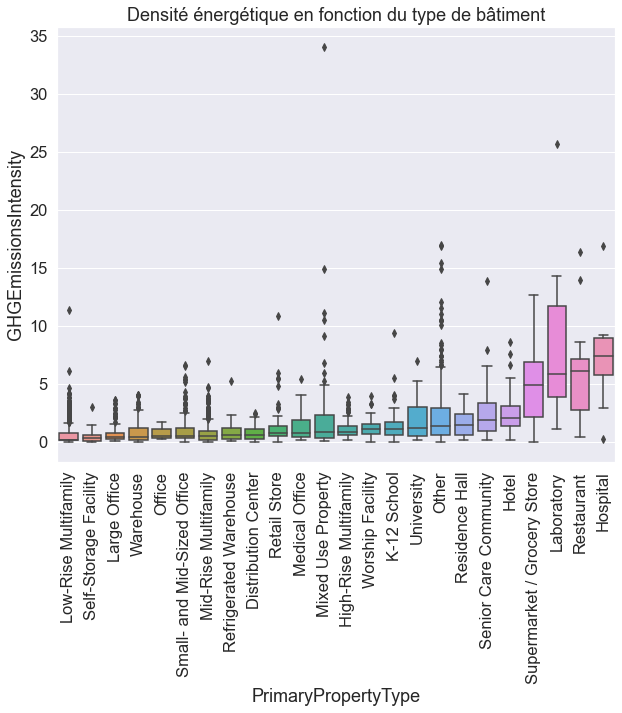

In [45]:
# Ajuster la taille de la figure
plt.figure(figsize=(10,8))

# Créer un graphique en boîte (boxplot)
sns.boxplot(x="PrimaryPropertyType", y="GHGEmissionsIntensity", data=data)

# Tourner les étiquettes de l'axe x pour une meilleure lisibilité
plt.xticks(rotation=90)

# Définir le titre du graphique
plt.title("Densité énergétique en fonction du type de bâtiment")

# Afficher le graphique
plt.show()


In [46]:
corr_matrix = data.corr().abs()

# Identifier les paires de variables fortement corrélées
threshold = 0.8
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

strongly_correlated_pairs = []
for col in upper_tri.columns:
    for row in upper_tri.index:
        if upper_tri.loc[row, col] > threshold:
            strongly_correlated_pairs.append((row, col, upper_tri.loc[row, col]))

# Afficher les paires de variables fortement corrélées dans l'ordre décroissant
print("Paires de variables fortement corrélées (supérieures à {}):".format(threshold))
for pair in strongly_correlated_pairs:
    print(" - {} et {} (corrélation: {:.2f})".format(pair[0], pair[1], pair[2]))

Paires de variables fortement corrélées (supérieures à 0.8):
 - PropertyGFATotal et PropertyGFABuilding(s) (corrélation: 0.99)
 - PropertyGFATotal et LargestPropertyUseTypeGFA (corrélation: 0.97)
 - PropertyGFABuilding(s) et LargestPropertyUseTypeGFA (corrélation: 0.98)
 - PropertyGFATotal et SecondLargestPropertyUseTypeGFA (corrélation: 0.81)
 - SiteEUI(kBtu/sf) et SiteEUIWN(kBtu/sf) (corrélation: 0.99)
 - SiteEUI(kBtu/sf) et SourceEUI(kBtu/sf) (corrélation: 0.94)
 - SiteEUIWN(kBtu/sf) et SourceEUI(kBtu/sf) (corrélation: 0.93)
 - SiteEUI(kBtu/sf) et SourceEUIWN(kBtu/sf) (corrélation: 0.94)
 - SiteEUIWN(kBtu/sf) et SourceEUIWN(kBtu/sf) (corrélation: 0.94)
 - SourceEUI(kBtu/sf) et SourceEUIWN(kBtu/sf) (corrélation: 0.99)
 - PropertyGFABuilding(s) et SiteEnergyUse(kBtu) (corrélation: 0.81)
 - LargestPropertyUseTypeGFA et SiteEnergyUse(kBtu) (corrélation: 0.84)
 - PropertyGFATotal et Electricity(kWh) (corrélation: 0.85)
 - PropertyGFABuilding(s) et Electricity(kWh) (corrélation: 0.86)
 - 

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong>  on a des colonnes très similaires/doublons qu'on va pouvoir supprimer pour l'étude <br> telles que NaturalGas(therms)','Electricity(kWh)’
    <br> Notamment les colonnes avec WN<br><br>
    Corrélation importante entre : <br>PropertyGFATotal et PropertyGFABuilding(s) / LargestPropertyUseTypeGFA <br>Corrélation importante entre PropertyGFABuilding(s) et LargestPropertyUseTypeGFA <br>Corrélation importante entre TotalGHEmissions et SiteEnergyUseWN(kBtu) aussi les variables cibles
</p> 


In [47]:
cols = data.columns.to_list()

In [48]:
cols

['OSEBuildingID',
 'DataYear',
 'BuildingType',
 'PrimaryPropertyType',
 'PropertyName',
 'Address',
 'City',
 'State',
 'ZipCode',
 'TaxParcelIdentificationNumber',
 'CouncilDistrictCode',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'PropertyGFAParking',
 'PropertyGFABuilding(s)',
 'ListOfAllPropertyUseTypes',
 'LargestPropertyUseType',
 'LargestPropertyUseTypeGFA',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'YearsENERGYSTARCertified',
 'ENERGYSTARScore',
 'SiteEUI(kBtu/sf)',
 'SiteEUIWN(kBtu/sf)',
 'SourceEUI(kBtu/sf)',
 'SourceEUIWN(kBtu/sf)',
 'SiteEnergyUse(kBtu)',
 'SiteEnergyUseWN(kBtu)',
 'SteamUse(kBtu)',
 'Electricity(kWh)',
 'Electricity(kBtu)',
 'NaturalGas(therms)',
 'NaturalGas(kBtu)',
 'DefaultData',
 'Comments',
 'ComplianceStatus',
 'Outlier',
 'TotalGHGEmissions',
 'GHGEmissionsIntensity',
 'EnergyUs

# Choix des colonnes

<div style="background-color:orange; color:dark;"> 
Lister les variables utiles/pas utiles/potentiellement utiles...<br>
</div>


## Identification des colonnes

## Les colonnes

| Colonne | Description |
| ------- | ----------- |
| OSEBuildingID | Identifiant unique de chaque bâtiment. |
| DataYear | Année à laquelle les données ont été collectées. |
| BuildingType | Type de bâtiment (commercial, résidentiel, etc.). |
| PrimaryPropertyType | Type de propriété principale (hôtel, bureau, hôpital, etc.). |
| PropertyName | Nom de la propriété. |
| Address | Adresse de la propriété. |
| City | Ville de la propriété. |
| State | État de la propriété. |
| ZipCode | Code postal de la propriété. |
| TaxParcelIdentificationNumber | Numéro d'identification fiscale de la propriété. |
| CouncilDistrictCode | Code de district du conseil pour la propriété. |
| Neighborhood | Quartier où se trouve la propriété. |
| Latitude | Latitude de la propriété. |
| Longitude | Longitude de la propriété. |
| YearBuilt | Année de construction de la propriété. |
| NumberofBuildings | Nombre de bâtiments sur le site de la propriété. |
| NumberofFloors | Nombre d'étages de la propriété. |
| PropertyGFATotal | Surface brute de la propriété, y compris les parkings et autres. |
| PropertyGFAParking | Surface brute de stationnement de la propriété. |
| PropertyGFABuilding(s) | Surface brute des bâtiments de la propriété. |
| ListOfAllPropertyUseTypes | Liste de tous les types d'utilisation de la propriété. |
| LargestPropertyUseType | Le type d'utilisation principal de la propriété. |
| LargestPropertyUseTypeGFA | Surface brute d'utilisation principale de la propriété. |
| SecondLargestPropertyUseType | Deuxième plus grand type d'utilisation de la propriété. |
| SecondLargestPropertyUseTypeGFA | Surface brute du deuxième plus grand type d'utilisation de la propriété. |
| ThirdLargestPropertyUseType | Troisième plus grand type d'utilisation de la propriété. |
| ThirdLargestPropertyUseTypeGFA | Surface brute du troisième plus grand type d'utilisation de la propriété. |
| YearsENERGYSTARCertified | Nombre d'années pendant lesquelles la propriété a été certifiée ENERGY STAR. |
| ENERGYSTARScore | Score ENERGY STAR de la propriété. |
| SiteEUI(kBtu/sf) | Indicateur de la consommation d'énergie du site de la propriété (en kBtu/ft²). |
| SiteEUIWN(kBtu/sf) | Indicateur de la consommation d'énergie du site de la propriété pondéré en fonction des conditions météorologiques (en kBtu/ft²). |
| SourceEUI(kBtu/sf) | Indicateur de la consommation d'énergie de la propriété en amont (en kBtu/ft²). |
| SourceEUIWN(kBtu/sf) | Indicateur de la consommation d'énergie de la propriété en amont pondéré en fonction des conditions météorologiques (en kBtu/ft²). |
| SiteEnergyUse(kBtu) | Consommation d'énergie du site de la propriété (en kBtu). |
| SiteEnergyUseWN(kBtu) | Consommation d'énergie du site de la propriété pondérée
| SteamUse(kBtu)              | Consommation de vapeur totale en BTU                                       |
| <font color="red">Electricity(kWh)    </color>        |<font color="red"> Consommation d'électricité totale en kWh </color>|
| <font color="red">Electricity(kBtu)   </color>       | <font color="red">Consommation d'électricité totale en BTU      </color>                             |
| NaturalGas(therms)          | Consommation de gaz naturel totale en therms                               |
| NaturalGas(kBtu)            | Consommation de gaz naturel totale en BTU                                  |




### Filtre sur Building Type pour garder les bâtiments non destinés à l'habitation

In [49]:
data['BuildingType'].unique()

array(['NonResidential', 'Nonresidential COS', 'Multifamily MR (5-9)',
       'SPS-District K-12', 'Campus', 'Multifamily LR (1-4)',
       'Multifamily HR (10+)', 'Nonresidential WA'], dtype=object)

<div style="background-color:orange; color:dark;"> • utile :
</div>

| Attribut                    | Description                                                                 |
|-----------------------------|-----------------------------------------------------------------------------|
| OSEBuildingID              | Identifiant unique de chaque bâtiment                                      |
| BuildingType                | Type de bâtiment (commercial, industriel, etc.)                            |
| PrimaryPropertyType         | Type de propriété principale (hôtel, bureau, etc.)                         |
| Latitude                    | Coordonnée de latitude de l'emplacement du bâtiment                        |
| Longitude                   | Coordonnée de longitude de l'emplacement du bâtiment                       |
| YearBuilt                   | Année de construction du bâtiment                                          |
| NumberofBuildings           | Nombre total de bâtiments dans la propriété                                |
| NumberofFloors              | Nombre total d'étages dans le bâtiment                                     |
| <font color="blue">PropertyGFATotal </color>           | Surface brute de la propriété, y compris les parkings et autres                           |
| PropertyGFAParking          | Surface brute du parking                                 |
| <font color="blue">PropertyGFABuilding(s)</color>       | Surface brute hors œuvre totale du bâtiment                                |
| LargestPropertyUseType      | Type d'utilisation principal de la propriété                               |
| LargestPropertyUseTypeGFA   | Surface brute hors œuvre totale de l'utilisation principale de la propriété |
| SiteEUI(kBtu/sf)            | Consommation d'énergie par unité de surface du site                        |
| SourceEUI(kBtu/sf)          | Consommation d'énergie par unité de surface source                         |
| SiteEnergyUse(kBtu)         | Consommation d'énergie totale du site en BTU                               |
| SteamUse(kBtu)              | Consommation de vapeur totale en BTU                                       |
| <font color="red">Electricity(kWh)    </color>        |<font color="red"> Consommation d'électricité totale en kWh </color>|
| <font color="red">Electricity(kBtu)   </color>       | <font color="red">Consommation d'électricité totale en BTU      </color>                             |
| NaturalGas(therms)          | Consommation de gaz naturel totale en therms                               |
| NaturalGas(kBtu)            | Consommation de gaz naturel totale en BTU                                  |
| ENERGYSTARScore             | Score ENERGY STAR de la propriété (intéressant à évaluer)                  |


<div style="background-color:orange; color:dark;"> • potentiellement pas utile :
</div>

| Attribut                    | Description                                                                 |
|-----------------------------|-----------------------------------------------------------------------------|
| PropertyGFAParking             | surface brute hors œuvre totale du parking (selon la nature de la prédiction à réaliser, cette colonne pourrait ne pas être pertinente)                                    |
| ListOfAllPropertyUseTypes                | liste de tous les types d'utilisation de la propriété (selon la nature de la prédiction à réaliser, cette colonne pourrait ne pas être pertinente)                           |
| SecondLargestPropertyUseType        | deuxième type d'utilisation principal de la propriété      |
| SecondLargestPropertyUseTypeGFA      | surface brute hors œuvre totale de la deuxième utilisation principale de la propriété          |
| ThirdLargestPropertyUseType| troisième type d'utilisation principal de la propriété        |
| ThirdLargestPropertyUseTypeGFA| troisième type d'utilisation principal de la propriété        | surface brute hors œuvre totale de la troisième utilisation principale de la propriété|
| YearsENERGYSTARCertified  |  nombre d'années où la propriété a été certifiée ENERGY STAR (selon l'intérêt jugé pour l'ENERGY STAR Score, cette colonne pourrait ne pas être pertinente)|


In [50]:
data.head(2)

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.0,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,0.000032
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.0,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,0.000028


<div style="background-color:orange; color:dark;"> • pas utile : les variables qui se terminent par WN (Weather Normalized) qui sont des corrections des conditions climatiques. 
</div>

| Attribut                    | Description                                                                 |
|-----------------------------|-----------------------------------------------------------------------------|
| SiteEUIWN(kBtu/sf) | consommation d'énergie par unité de surface du site ajustée par le climat                  |
| SiteEnergyUseWN(kBtu) | consommation d'énergie totale du site en BTU ajustée par le climat|
| SourceEUIWN(kBtu/sf) | consommation d'énergie par unité de surface source ajustée par le climat |

In [51]:
data["ThirdLargestPropertyUseType"].unique()

array([nan, 'Restaurant', 'Swimming Pool', 'Data Center', 'Office',
       'Retail Store', 'Other - Entertainment/Public Assembly',
       'Non-Refrigerated Warehouse', 'Other', 'Distribution Center',
       'Food Service', 'Other - Services', 'Medical Office', 'Parking',
       'Other - Utility', 'Other - Lodging/Residential', 'K-12 School',
       'Fitness Center/Health Club/Gym', 'Social/Meeting Hall',
       'Pre-school/Daycare', 'Convenience Store without Gas Station',
       'Financial Office', 'Other - Restaurant/Bar', 'Other - Education',
       'Multifamily Housing', 'Laboratory', 'Bank Branch', 'Hotel',
       'Personal Services (Health/Beauty, Dry Cleaning, etc)',
       'Other - Recreation', 'Self-Storage Facility',
       'Other - Technology/Science', 'Refrigerated Warehouse',
       'Fast Food Restaurant', 'Bar/Nightclub',
       'Manufacturing/Industrial Plant', 'Food Sales',
       'Supermarket/Grocery Store', 'Other/Specialty Hospital',
       'Worship Facility', 'Stri

• Ccl pas utile :

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> <br>DefaultData : colonne qui peut contenir des informations inutiles pour la prédiction, car elle indique si les données ont été entrées manuellement ou automatiquement<br>
Comments : colonne qui peut contenir des commentaires non pertinents pour la prédiction<br>
Outlier : indique si la propriété est un outlier (données aberrantes), utile pour le nettoyage de données (on supprimera les outliers)<br>
ComplianceStatus : indique si la propriété est conforme aux réglementations en matière d'énergie, utile pour le nettoyage de données (on supprimera les données non compliant)
        </p>

In [52]:
data[cols].describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,3376.000000,3.376000e+03,3.356000e+03,1679.000000,596.000000,2533.000000,3369.000000,3370.000000,3367.000000,3367.000000,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000,3.367000e+03
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,8001.526066,8.683201e+04,7.917764e+04,28444.075817,11738.675166,67.918674,54.732116,57.033798,134.232848,137.783932,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916,2.806630e-05
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,32326.723928,2.079398e+05,2.017034e+05,54392.917928,29331.199286,26.873271,56.273124,57.163330,139.287554,139.109807,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452,5.870513e-05
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-2.100000,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000,-3.846154e-07
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,0.000000,2.775600e+04,2.509475e+04,5000.000000,2239.000000,53.000000,27.900000,29.400000,74.699997,78.400002,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000,4.153489e-06
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,0.000000,4.321600e+04,3.989400e+04,10664.000000,5043.000000,75.000000,38.599998,40.900002,96.199997,101.099998,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000,9.025853e-06
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,0.000000,8.427625e+04,7.620025e+04,26640.000000,10138.750000,90.000000,60.400002,64.275002,143.899994,148.349998,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000,2.887467e-05
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,686750.000000,459748.000000,100.000000,834.400024,834.400024,2620.000000,2620.000000,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000,1.325867e-03


# Nettoyage de données

<div style="background-color:orange; color:dark;"> Nettoyage des données, étapes :<br>
procéder à une réduction dimensionnelle dont la sélection se fera sur les éléments suivants :<br>
• Taux de remplissage<br>
• Variables fortement corrélées<br>
</div>

Données inutilisées : données d'identification trop précises


Propriétés : pas directement liées aux métriques d'émissions de CO2, donc peuvent être utilisées pour le modèle sans craindre une fuite de données. Certaines sont quantitatives, d'autres sont catégorielles et devront être encodées.


Métriques de performance énergétique : données liées aux métriques que nous voulons calculer avec notre modèle, donc ne doivent pas être utilisées comme données d'entrée pour le modèle. Cependant, nous pouvons extraire des données utiles de celles-ci.

Il est précisié dans le projet que seuls les bâtiments non destinés à l'habitation seront étudiés. 

Nous allons donc supprimer toutes les lignes correspondant à des habitations en nous basant sur la variable BuildingType.

## suppression des colonnes inintéressantes

### suppression des données d'habitation

In [53]:
data_clean = data[~data['BuildingType'].str.contains("Multifamily")]
print(data['BuildingType'].unique())
print(data_clean['BuildingType'].unique())

['NonResidential' 'Nonresidential COS' 'Multifamily MR (5-9)'
 'SPS-District K-12' 'Campus' 'Multifamily LR (1-4)'
 'Multifamily HR (10+)' 'Nonresidential WA']
['NonResidential' 'Nonresidential COS' 'SPS-District K-12' 'Campus'
 'Nonresidential WA']


### suppression des lignes où "Outlier" prend la valeur High

In [54]:
data_clean = data[data["Outlier"] != "High outlier"] #suppression des lignes où "Outlier" prend la valeur High

# Suppression de la colonne "Outlier"
data_clean = data_clean.drop(columns=["Outlier"])

print(data_clean.shape)


(3367, 46)


<div style="background-color:orange; color:dark;"> Supprimons les colonnes qui ne nous intéressent pas dans ce projet :

les variables qui se terminent par WN (Weather Normalized) qui sont des corrections des conditions climatiques. 

les variables redondantes Electricity(kWh) / Electricity(kBtu) NaturalGas(therms) / NaturalGas(kBtu)<br>
</div>

### suppression des données non conformes

In [55]:
# Suppression des données non compliant
data_clean = data_clean[~data_clean['ComplianceStatus'].isin(['Error - Correct Default Data', 'Missing Data', 'Non-Compliant'])]
data_clean.drop(columns=['ComplianceStatus'], inplace=True)

### Suppression des variables redondantes, WN names

| Attribut                    | Description                                                                 |
|-----------------------------|-----------------------------------------------------------------------------|
| OSEBuildingID              | Identifiant unique de chaque bâtiment                                      |
| BuildingType                | Type de bâtiment (commercial, industriel, etc.)                            |
| PrimaryPropertyType         | Type de propriété principale (hôtel, bureau, etc.)                         |
| Latitude                    | Coordonnée de latitude de l'emplacement du bâtiment                        |
| Longitude                   | Coordonnée de longitude de l'emplacement du bâtiment                       |
| YearBuilt                   | Année de construction du bâtiment                                          |
| NumberofBuildings           | Nombre total de bâtiments dans la propriété                                |
| NumberofFloors              | Nombre total d'étages dans le bâtiment                                     |
| PropertyGFATotal            | Surface brute hors œuvre totale de la propriété                            |
| PropertyGFAParking          | Surface brute hors œuvre totale du parking                                 |
| PropertyGFABuilding(s)      | Surface brute hors œuvre totale du bâtiment                                |
| LargestPropertyUseType      | Type d'utilisation principal de la propriété                               |
| LargestPropertyUseTypeGFA   | Surface brute hors œuvre totale de l'utilisation principale de la propriété |
| SiteEUI(kBtu/sf)            | Consommation d'énergie par unité de surface du site                        |
| SourceEUI(kBtu/sf)          | Consommation d'énergie par unité de surface source                         |
| SiteEnergyUse(kBtu)         | Consommation d'énergie totale du site en BTU                               |
| SteamUse(kBtu)              | Consommation de vapeur totale en BTU                                       |
| Electricity(kWh)            | Consommation d'électricité totale en kWh                                   |
| Electricity(kBtu)           | Consommation d'électricité totale en BTU                                   |
| NaturalGas(therms)          | Consommation de gaz naturel totale en therms                               |
| NaturalGas(kBtu)            | Consommation de gaz naturel totale en BTU                                  |
| ENERGYSTARScore             | Score ENERGY STAR de la propriété (intéressant à évaluer)                  |


In [56]:
data.columns.to_list()

['OSEBuildingID',
 'DataYear',
 'BuildingType',
 'PrimaryPropertyType',
 'PropertyName',
 'Address',
 'City',
 'State',
 'ZipCode',
 'TaxParcelIdentificationNumber',
 'CouncilDistrictCode',
 'Neighborhood',
 'Latitude',
 'Longitude',
 'YearBuilt',
 'NumberofBuildings',
 'NumberofFloors',
 'PropertyGFATotal',
 'PropertyGFAParking',
 'PropertyGFABuilding(s)',
 'ListOfAllPropertyUseTypes',
 'LargestPropertyUseType',
 'LargestPropertyUseTypeGFA',
 'SecondLargestPropertyUseType',
 'SecondLargestPropertyUseTypeGFA',
 'ThirdLargestPropertyUseType',
 'ThirdLargestPropertyUseTypeGFA',
 'YearsENERGYSTARCertified',
 'ENERGYSTARScore',
 'SiteEUI(kBtu/sf)',
 'SiteEUIWN(kBtu/sf)',
 'SourceEUI(kBtu/sf)',
 'SourceEUIWN(kBtu/sf)',
 'SiteEnergyUse(kBtu)',
 'SiteEnergyUseWN(kBtu)',
 'SteamUse(kBtu)',
 'Electricity(kWh)',
 'Electricity(kBtu)',
 'NaturalGas(therms)',
 'NaturalGas(kBtu)',
 'DefaultData',
 'Comments',
 'ComplianceStatus',
 'Outlier',
 'TotalGHGEmissions',
 'GHGEmissionsIntensity',
 'EnergyUs

In [57]:
# suppressions des variables qui ne nous intéressent pas
data_clean.drop(['State','Comments','ZipCode','City','PropertyName',
 'Address','TaxParcelIdentificationNumber',
 'CouncilDistrictCode'], axis=1, inplace=True)

#Suppression des variables redondantes
redundant_features = ['NaturalGas(therms)','Electricity(kWh)','SiteEUIWN(kBtu/sf)']
data_clean.drop(redundant_features, axis=1, inplace=True)

# Find columns containing 'WN' in their names
columns_to_drop = [column for column in data_clean.columns if 'WN' in column]


#ENERGYSTARScore
data_clean.drop("ENERGYSTARScore", axis=1, inplace=True)

# Drop the columns from data_clean
data_clean = data_clean.drop(columns_to_drop, axis=1)


# Nouvelle liste des colonnes numériques
num_columns = list(data.select_dtypes(include='float64').columns)

### suppression des colonnes vides a plus de 80%

<div style="background-color:orange; color:dark;"> On calcule la proportion de données manquantes pour chaque colonne
</div>

In [58]:
data_clean = data_clean[data_clean.columns[data_clean.isna().sum()/data_clean.shape[0]<0.8]]

In [59]:
missing_values = data_clean.isnull().sum()
total_values = np.product(data_clean.shape)
missing_percent = (missing_values.sum()/total_values) * 100

print(f'Le taux de valeurs manquantes dans le dataset est: {missing_percent}%')


Le taux de valeurs manquantes dans le dataset est: 3.5514081060639766%


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> 8.509311235854941%% de données manquantes
</p> 

In [60]:
print(data.shape)
data.head(2)

(3376, 47)


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.0,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83,0.000032
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.0,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86,0.000028


In [61]:
print(data_clean.shape)
data_clean.head(2)

(3211, 28)


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,NonResidential,Hotel,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,81.699997,182.500000,7226362.5,2003882.0,3946027.0,1276453.0,False,249.98,2.83,0.000032
1,2,2016,NonResidential,Hotel,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,94.800003,176.100006,8387933.0,0.0,3242851.0,5145082.0,False,295.86,2.86,0.000028


### Gestion des outliers

### valeurs aberrantes

<div style="background-color:orange; color:dark;"> valeurs aberrantes
on remplace les valeurs negatives des données numériques par nan
! attention longutude lat ok neg
et suppr lignes où target neg supr lignes
</div>

In [62]:
def is_numeric(value):
    return isinstance(value, (int, float, np.number))

def replace_negative_except_columns(x, columns):
    if x.name in columns:
        return x
    return x.apply(lambda v: np.nan if (is_numeric(v) and v < 0) else v)

# Remplace les valeurs négatives par NaN, sauf pour les colonnes spécifiées
columns_to_keep = ["Longitude", "Latitude", "ZipCode"]
data_clean = data_clean.apply(lambda x: replace_negative_except_columns(x, columns_to_keep))

In [63]:
data_clean.describe()

,OSEBuildingID,DataYear,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
count,3211.000000,3211.0,3211.000000,3211.000000,3211.000000,3208.000000,3211.000000,3.211000e+03,3211.000000,3.211000e+03,3.196000e+03,1647.000000,3211.000000,3207.000000,3.211000e+03,3.207000e+03,3.206000e+03,3.207000e+03,3206.000000,3206.000000,3206.000000
mean,21414.844285,2016.0,47.624544,-122.335136,1968.739645,1.110973,4.804734,9.579423e+04,8363.015883,8.743122e+04,7.945189e+04,28235.887248,55.624229,136.583536,5.533766e+06,2.853587e+05,3.801742e+06,1.387511e+06,122.250256,1.189523,0.000029
std,12141.860393,0.0,0.047004,0.026574,33.163544,2.158983,5.591453,2.227902e+05,33090.184050,2.115593e+05,2.055745e+05,52296.359208,56.722463,139.761916,2.211048e+07,4.005355e+06,1.518654e+07,6.866490e+06,551.616631,1.843830,0.000060
min,1.000000,2016.0,47.502240,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,0.000000,1.400000,0.000000,5.713320e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,20072.500000,2016.0,47.601050,-122.350425,1948.000000,1.000000,2.000000,2.830000e+04,0.000000,2.756350e+04,2.498950e+04,5000.000000,28.100000,75.549999,9.368353e+05,0.000000e+00,6.432570e+05,0.000000e+00,9.650000,0.210000,0.000004
50%,23170.000000,2016.0,47.618910,-122.332630,1975.000000,1.000000,4.000000,4.379400e+04,0.000000,4.281600e+04,3.900000e+04,10800.000000,39.299999,97.699997,1.808401e+06,0.000000e+00,1.187300e+06,3.194000e+05,33.920000,0.615000,0.000009
75%,26010.500000,2016.0,47.656745,-122.320200,1997.000000,1.000000,5.000000,9.154000e+04,0.000000,8.449850e+04,7.676675e+04,26770.000000,61.500000,146.600006,4.266934e+06,0.000000e+00,2.889957e+06,1.183018e+06,94.427500,1.380000,0.000030
max,50226.000000,2016.0,47.733870,-122.260280,2015.000000,111.000000,99.000000,9.320156e+06,512608.000000,9.320156e+06,9.320156e+06,639931.000000,834.400024,2620.000000,8.739237e+08,1.349435e+08,6.570744e+08,2.979090e+08,16870.980000,34.090000,0.001326


# variables cibles :

﻿ Consommation totale des bâtiments SiteEnergyUseWN(kBtu)
﻿ Emissions totales des bâtiments TotalGHGEmissions

In [64]:
data_clean["SiteEnergyUse(kBtu)"].median()

1808401.375

In [65]:
data_clean["TotalGHGEmissions"].median()

33.92

In [66]:
data_clean.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM
0,1,2016,NonResidential,Hotel,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,81.699997,182.500000,7226362.5,2003882.00,3946027.0,1276453.0,False,249.98,2.83,0.000032
1,2,2016,NonResidential,Hotel,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,94.800003,176.100006,8387933.0,0.00,3242851.0,5145082.0,False,295.86,2.86,0.000028
2,3,2016,NonResidential,Hotel,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,96.000000,241.899994,72587024.0,21566554.00,49526664.0,1493800.0,False,2089.28,2.19,0.000002
3,5,2016,NonResidential,Hotel,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,110.800003,216.199997,6794584.0,2214446.25,2768924.0,1811213.0,False,286.43,4.67,0.000076
4,8,2016,NonResidential,Hotel,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,114.800003,211.399994,14172606.0,0.00,5368607.0,8803998.0,False,505.01,2.88,0.000016


In [67]:
import pandas as pd


# Calculer la corrélation de chaque colonne avec les variables cibles
correlations = data_clean.corr()[["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]]
correlations = correlations.drop(["SiteEnergyUse(kBtu)", "TotalGHGEmissions"])

# Afficher les résultats par ordre décroissant
correlations = correlations.sort_values(by=["SiteEnergyUse(kBtu)", "TotalGHGEmissions"], ascending=False)
print(correlations)


                                 SiteEnergyUse(kBtu)  TotalGHGEmissions
Electricity(kBtu)                           0.956682           0.691762
LargestPropertyUseTypeGFA                   0.840645           0.580889
PropertyGFABuilding(s)                      0.817905           0.548944
PropertyGFATotal                            0.801917           0.534302
NumberofBuildings                           0.691678           0.405769
SecondLargestPropertyUseTypeGFA             0.663873           0.533329
SteamUse(kBtu)                              0.605118           0.683507
NaturalGas(kBtu)                            0.514514           0.732122
GHGEmissionsIntensity                       0.311276           0.470983
SiteEUI(kBtu/sf)                            0.298140           0.286644
SourceEUI(kBtu/sf)                          0.294395           0.231018
NumberofFloors                              0.204707           0.135187
PropertyGFAParking                          0.169956           0

In [68]:
# Vérification des doublons dans la colonne "OSEBuildingID"
print("Nombre de valeurs uniques dans la colonne 'OSEBuildingID':", len(data_clean['OSEBuildingID'].unique()))
print("Nombre total de valeurs dans la colonne 'OSEBuildingID':", len(data_clean['OSEBuildingID']))

# Suppression des doublons dans la colonne "OSEBuildingID"
data_clean.drop_duplicates(subset=['OSEBuildingID'], inplace=True)


Nombre de valeurs uniques dans la colonne 'OSEBuildingID': 3211
Nombre total de valeurs dans la colonne 'OSEBuildingID': 3211


### analyse distribution des variables cibles

### SiteEnergyUse(kBtu)

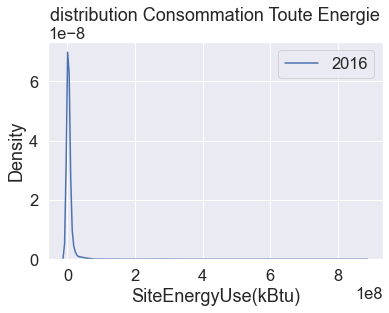

In [69]:
plt.title('distribution Consommation Toute Energie')
sns.kdeplot(data_clean['SiteEnergyUse(kBtu)'], label = '2016')
plt.legend()
plt.show()

### TotalGHGEmissions

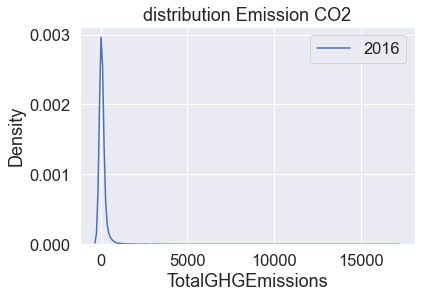

In [70]:
plt.title('distribution Emission CO2')
sns.kdeplot(data_clean['TotalGHGEmissions'], label='2016')
plt.legend()
plt.show()

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_37975/723768588.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(np.log(data[label][data[label] > 0]), bins=int(1 + np.log2(len(data))))
/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_37975/723768588.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6

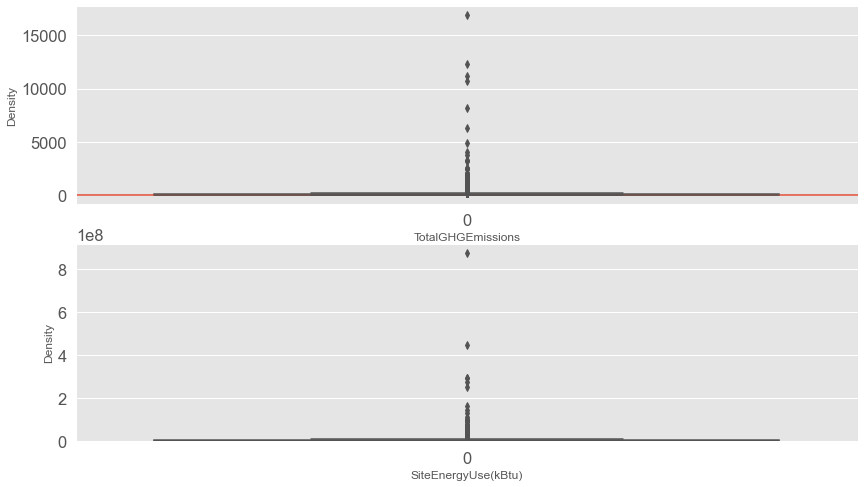

In [71]:
plt.style.use('ggplot')

fig = plt.figure(1, figsize=(14, 8))
for i,label in enumerate(["TotalGHGEmissions", "SiteEnergyUse(kBtu)"]) :
    plt.subplot(2,1,i+1)
    sns.distplot(np.log(data[label][data[label] > 0]), bins=int(1 + np.log2(len(data))))
    plt.subplot(2,1,i+1)
    sns.boxplot(data[label], orient="v")
plt.show()



# Analyse bivariée

"SecondLargestPropertyUseType", "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseType" et "ThirdLargestPropertyUseTypeGFA" peut être bénéfique pour la modélisation. 

Cependant, si ces colonnes ont de nombreuses valeurs manquantes ou si leur contribution à la prédiction des émissions de CO2 et de la consommation totale d'énergie est négligeable, il peut être préférable de les supprimer pour simplifier le jeu de données et améliorer les performances de la modélisation. 

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/pandas/util/_decorators.py:311: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return func(*args, **kwargs)


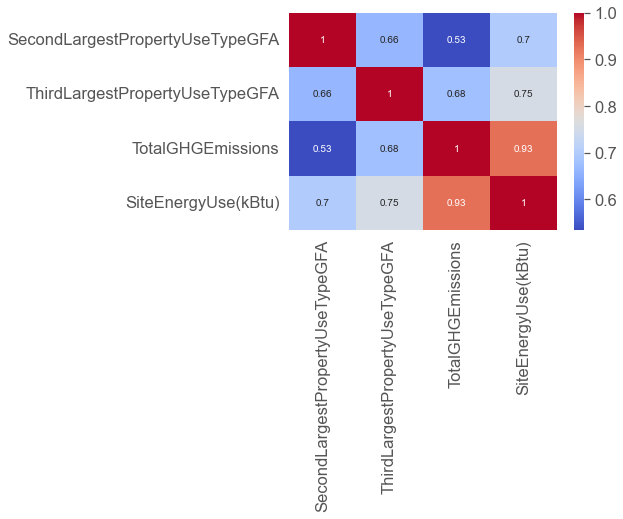

In [75]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Sélection des colonnes pertinentes
df = data[['SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA',
           'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA',
           'TotalGHGEmissions', 'SiteEnergyUse(kBtu)']]

# Suppression des lignes avec des valeurs manquantes
df.dropna(inplace=True)

# Calcul de la matrice de corrélation
corr_matrix = df.corr()

# Affichage de la matrice de corrélation
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()


Il est important de considérer chaque colonne de manière individuelle et de déterminer si elle peut apporter une valeur ajoutée à la modélisation ou si elle peut potentiellement conduire à une fuite de données.

## TotalGHGEmissions variables qualitatives

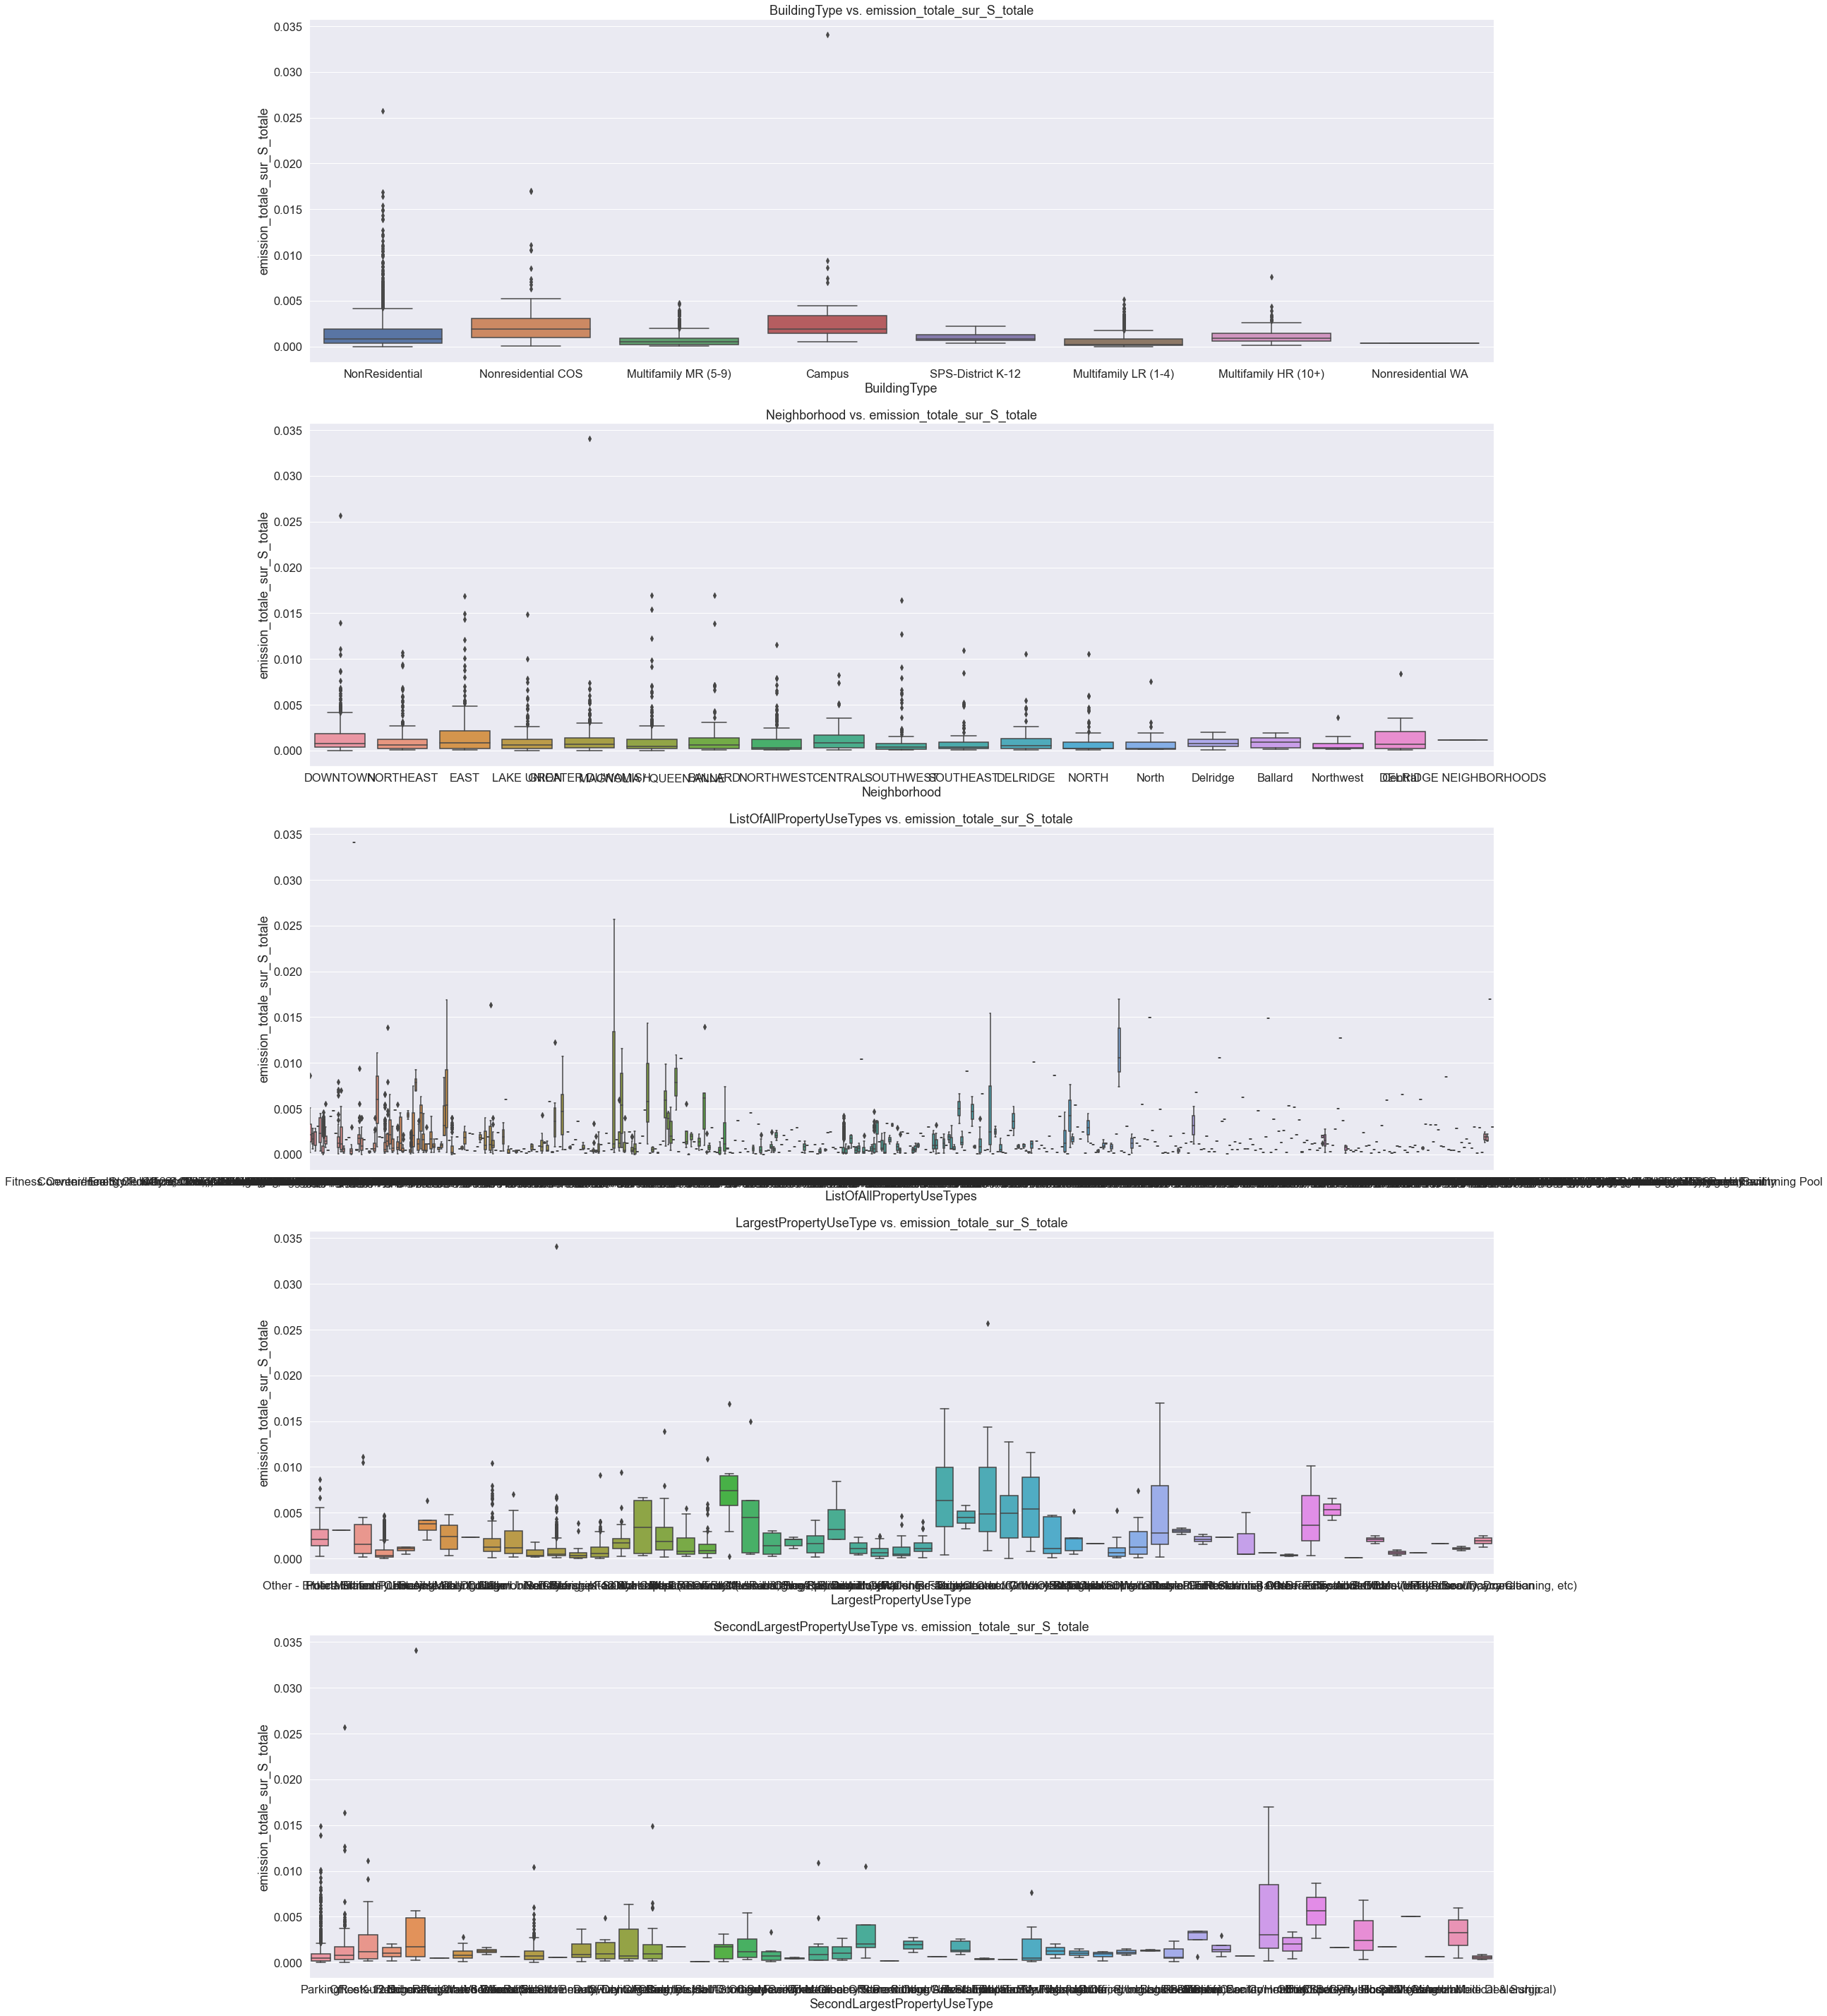

In [77]:
# Create the new column 'emission_totale_sur_S_totale'
data_clean['emission_totale_sur_S_totale'] = data_clean['TotalGHGEmissions'] / data_clean['PropertyGFATotal']

# Select qualitative columns
qualitative_columns = data_clean.select_dtypes(include=['object']).columns

sns.set(font_scale=1.5)

# Calculate the number of rows and columns for the subplots
n = len(qualitative_columns)
ncols = 1
nrows = n // ncols + (n % ncols > 0)

# Set the figure size
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))

# Iterate through qualitative_columns and create the boxplots
for idx, column in enumerate(qualitative_columns):
    row, col = idx // ncols, idx % ncols
    sns.boxplot(x=column, y='emission_totale_sur_S_totale', data=data_clean, ax=axes[row])
    chaine =  column + ' vs. emission_totale_sur_S_totale'
    axes[row].set_title(chaine)
    axes[row].set_xlabel(column)
    axes[row].set_ylabel('emission_totale_sur_S_totale')

# If there are empty subplots, remove their axes
for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> permet de voir que list of all property use type est trop nombreux
</p> 

CCl créer des features avec cluster , categories suppl ?


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Grande influence de l'usage des building second et third property sur l'émission totale de Co2
</p> 

In [78]:
# créer un nouveau dataframe pour stocker les premières occurrences non NaN
first_occurrences = pd.DataFrame(columns=data_clean.columns)

# parcourir les colonnes du dataframe
for col in data_clean.columns:
    # trouver la première occurrence non NaN de la colonne
    first_index = data_clean[col].first_valid_index()
    # ajouter la valeur de la première occurrence dans le nouveau dataframe
    first_occurrences[col] = pd.Series(data_clean.loc[first_index, col])

# afficher le nouveau dataframe
first_occurrences

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,SiteEUI(kBtu/sf),SourceEUI(kBtu/sf),SiteEnergyUse(kBtu),SteamUse(kBtu),Electricity(kBtu),NaturalGas(kBtu),DefaultData,TotalGHGEmissions,GHGEmissionsIntensity,EnergyUsePerSqM,emission_totale_sur_S_totale
0,1,2016,NonResidential,Hotel,DOWNTOWN,47.6122,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,Parking,15064.0,81.699997,182.5,7226362.5,2003882.0,3946027.0,1276453.0,False,249.98,2.83,0.000032,0.002827


In [79]:
first_occurrences.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'Neighborhood', 'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'SiteEUI(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SteamUse(kBtu)', 'Electricity(kBtu)', 'NaturalGas(kBtu)', 'DefaultData', 'TotalGHGEmissions', 'GHGEmissionsIntensity', 'EnergyUsePerSqM', 'emission_totale_sur_S_totale'], dtype='object')

### variables numériques qualitatives : ZipCode

## TotalGHGEmissions variables quantitatives

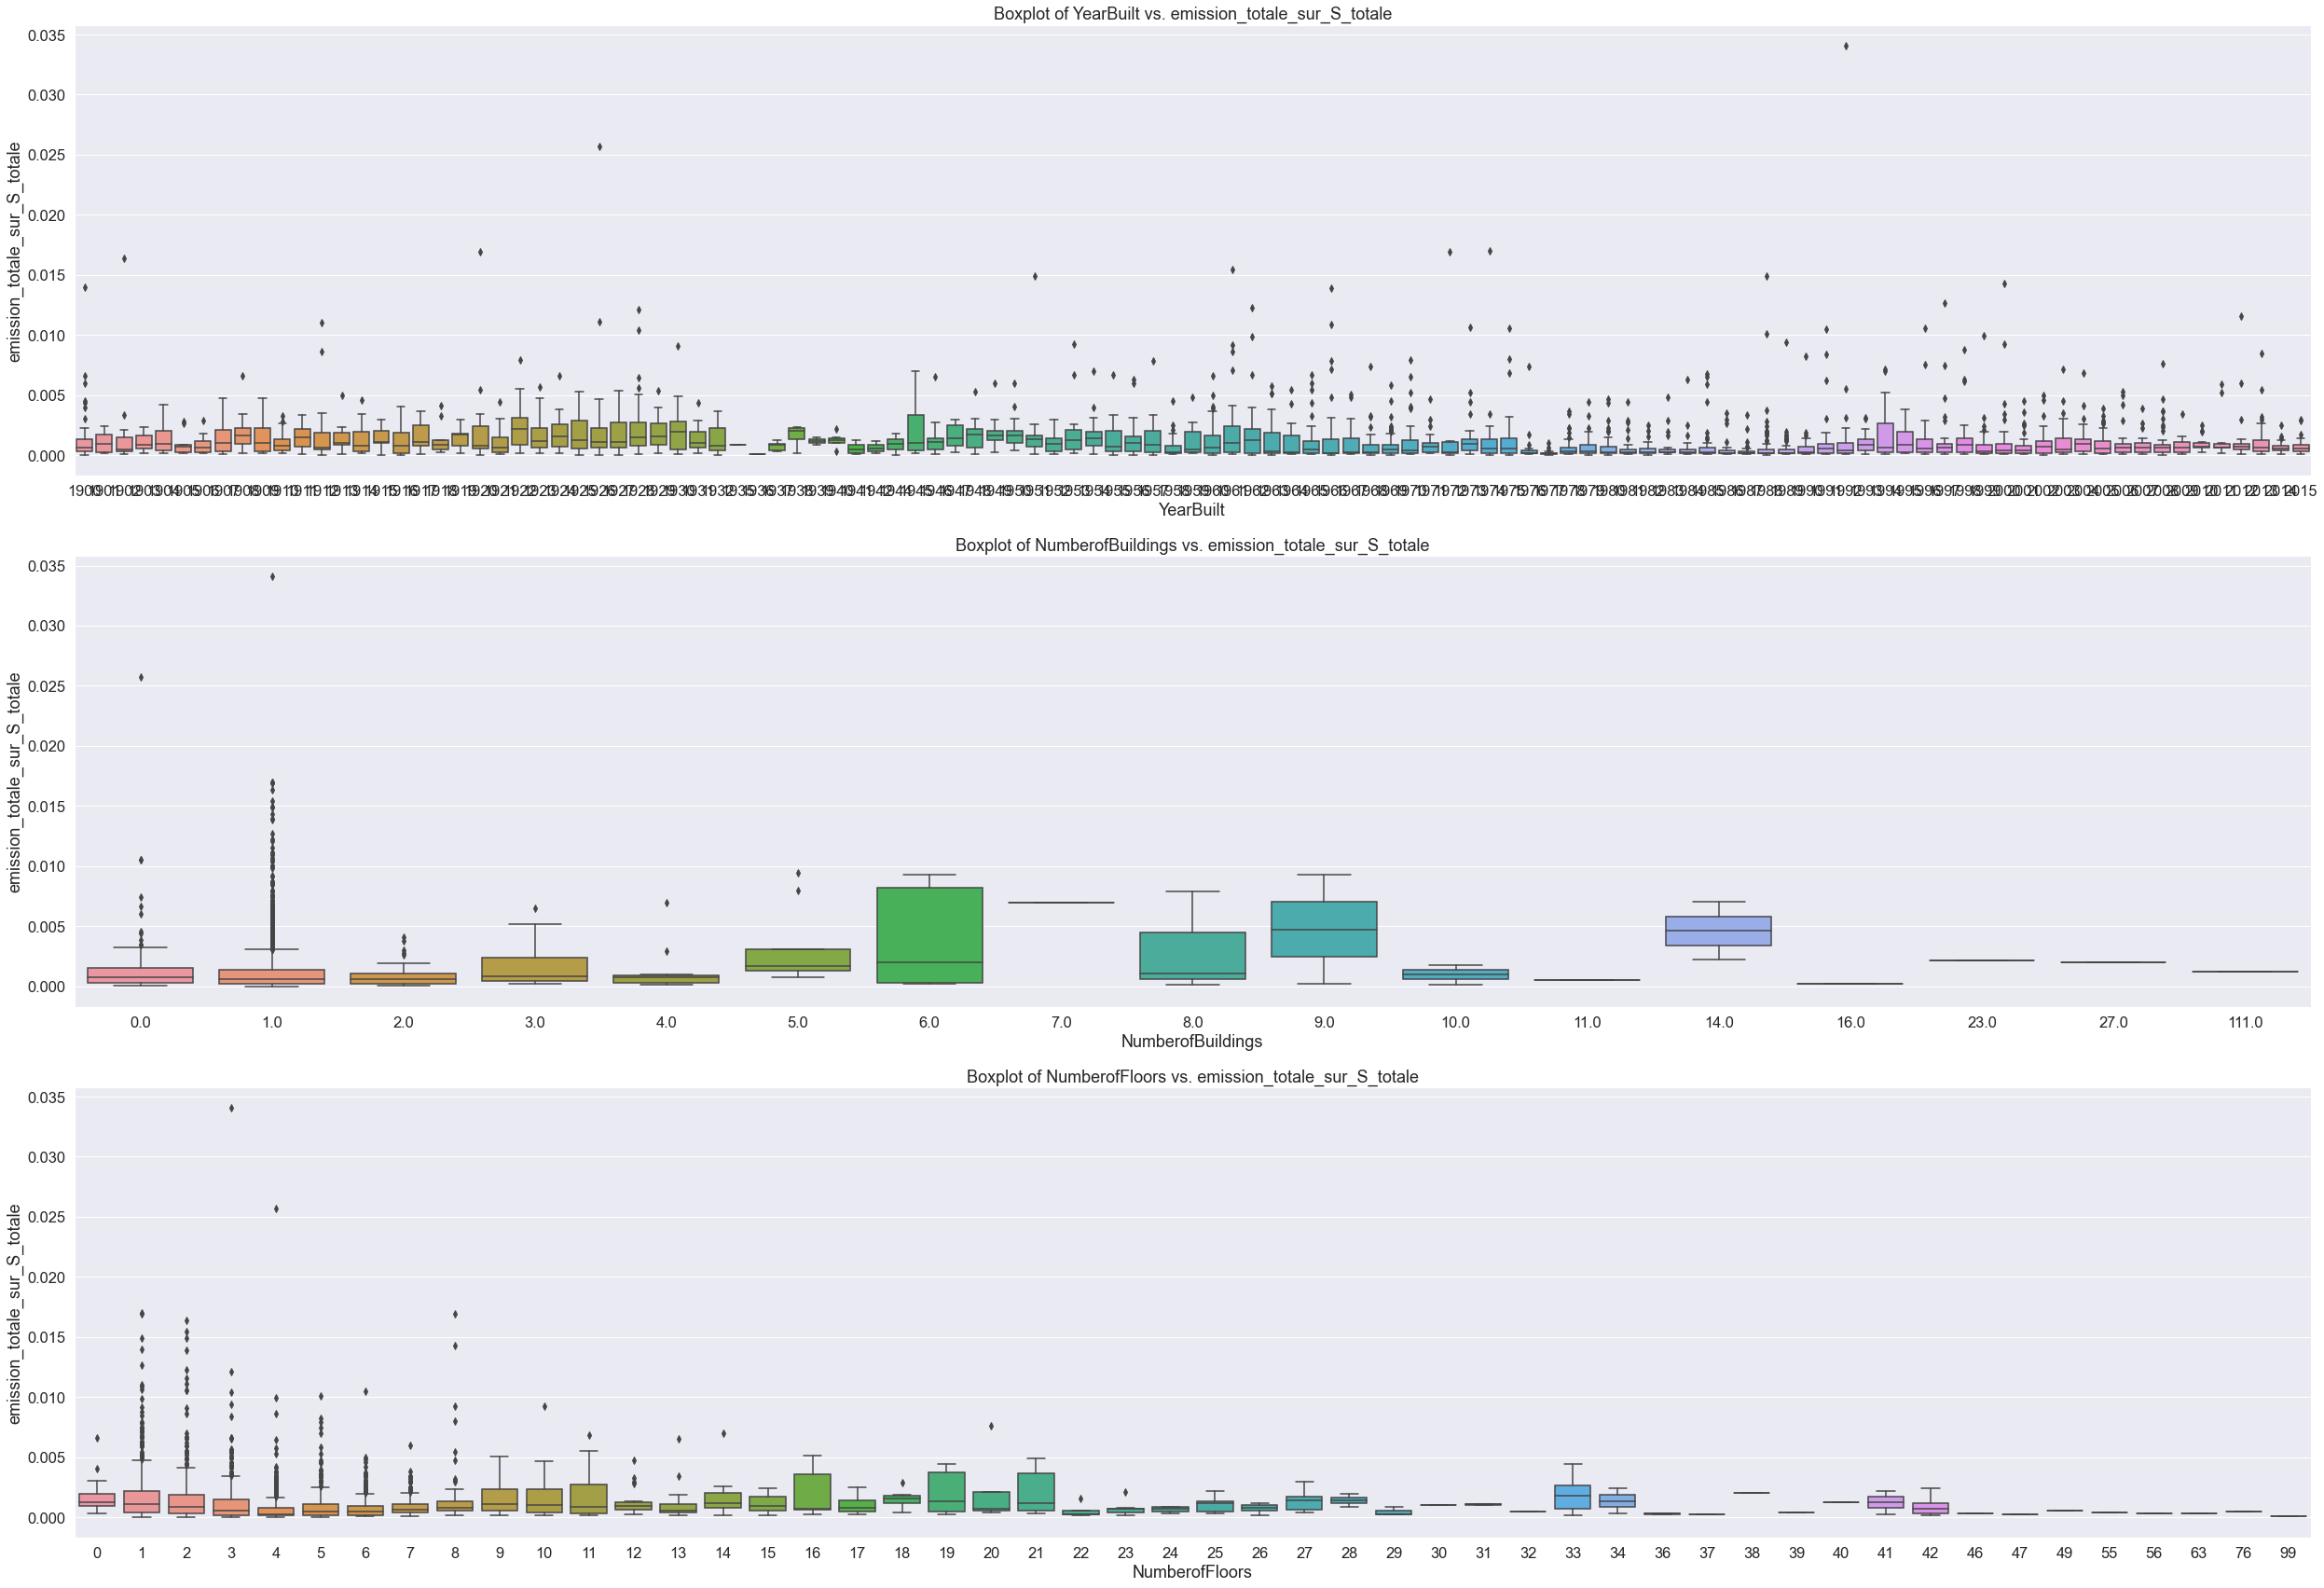

In [80]:
# Liste des colonnes discrètes
discrete_columns = ['YearBuilt', 'NumberofBuildings', 'NumberofFloors']

sns.set(font_scale=1.5)

# Calculate the number of rows and columns for the subplots
n = len(discrete_columns)
ncols = 1
nrows = n // ncols + (n % ncols > 0)

# Set the figure size
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))

# Iterate through discrete_columns and create the boxplots
for idx, column in enumerate(discrete_columns):
    row, col = idx // ncols, idx % ncols
    sns.boxplot(x=column, y='emission_totale_sur_S_totale', data=data_clean, ax=axes[row])
    chaine = 'Boxplot of ' + column + ' vs. emission_totale_sur_S_totale'
    axes[row].set_title(chaine)
    axes[row].set_xlabel(column)
    axes[row].set_ylabel('emission_totale_sur_S_totale')

# If there are empty subplots, remove their axes
for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> dur de trouver une tendance general avec nb de building floors year built etc
</p> 


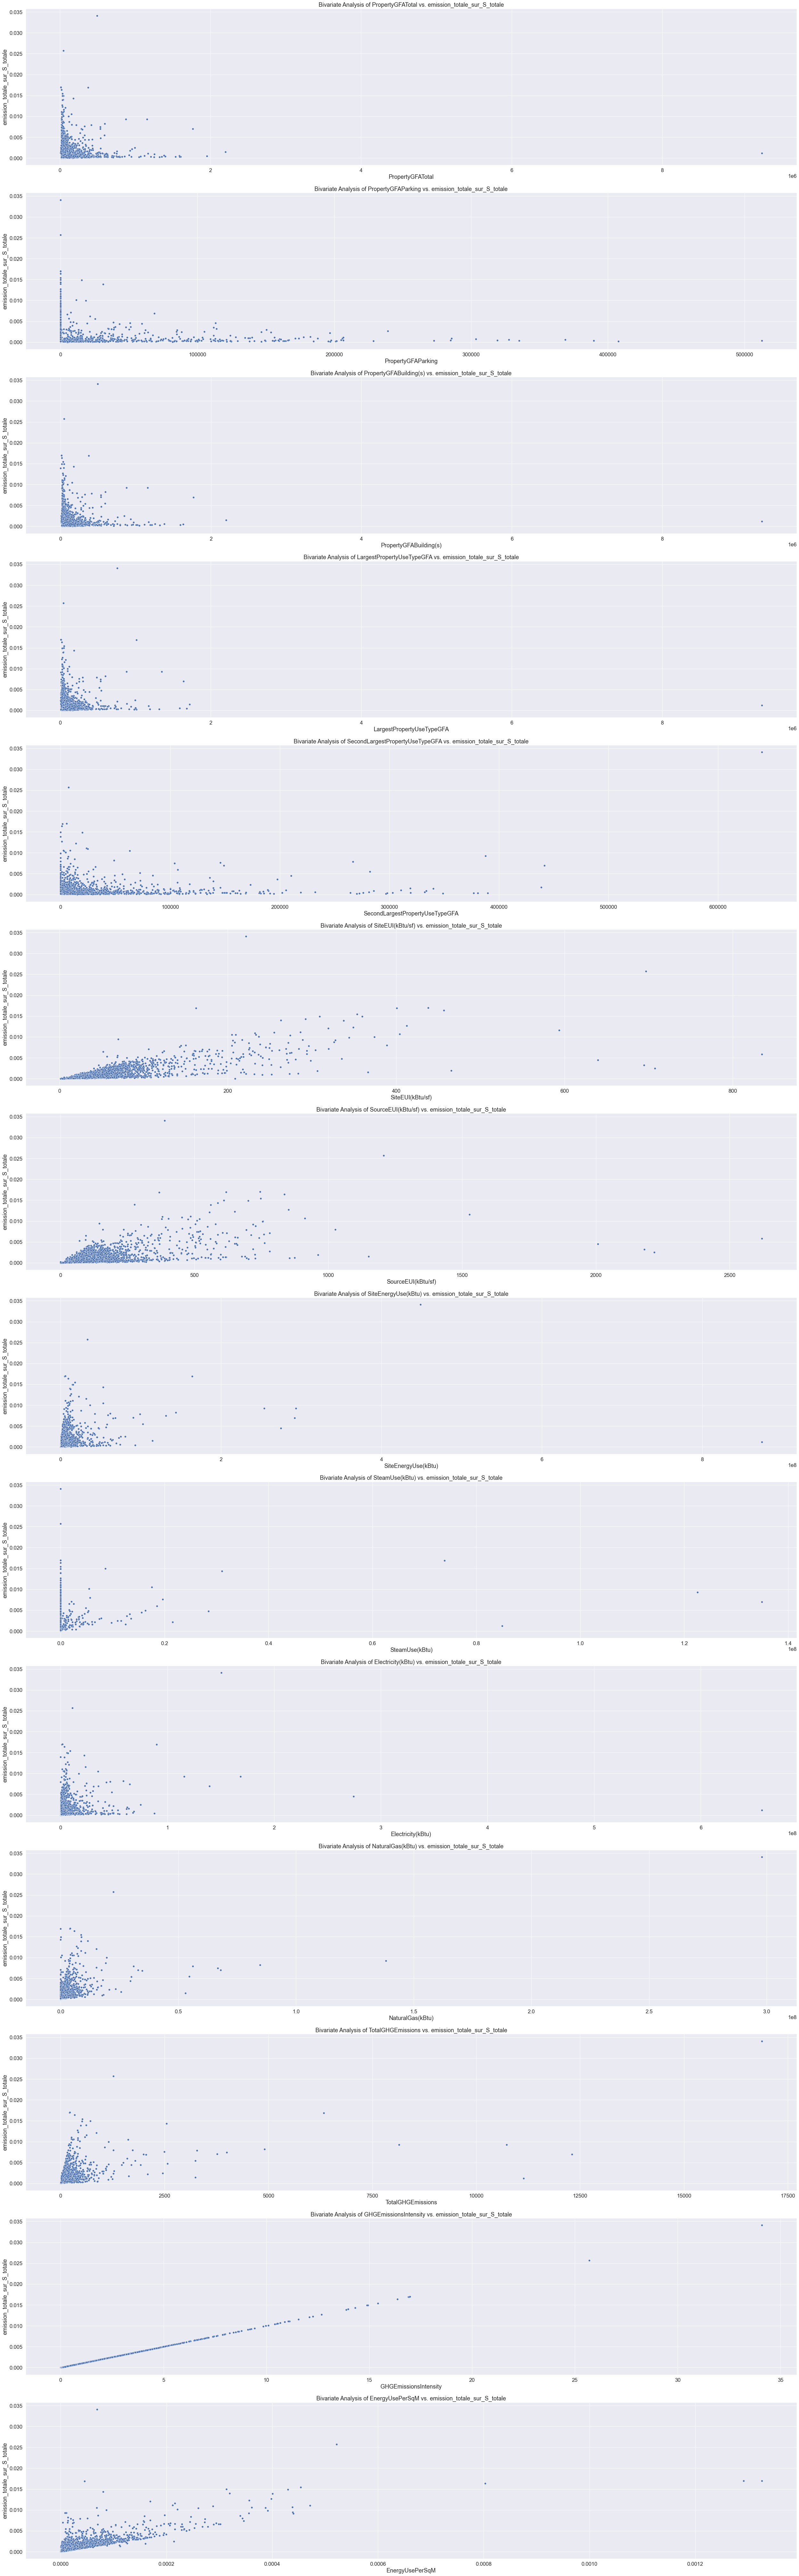

In [81]:
# Liste des colonnes à supprimer
columns_to_remove = ['OSEBuildingID', 'DataYear', 'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors']

# Sélectionner les colonnes quantitatives, en excluant les colonnes à supprimer et 'emission_totale_sur_S_totale'
quantitative_columns = data_clean.select_dtypes(include=['number']).columns
quantitative_columns = [col for col in quantitative_columns if col not in columns_to_remove and col != 'emission_totale_sur_S_totale']

sns.set(font_scale=1.5)

# Calculate the number of rows and columns for the subplots
n = len(quantitative_columns)
ncols = 1
nrows = n // ncols + (n % ncols > 0)

# Set the figure size
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))

# Iterate through quantitative_columns and create the scatterplots
for idx, column in enumerate(quantitative_columns):
    row, col = idx // ncols, idx % ncols
    sns.scatterplot(x=column, y='emission_totale_sur_S_totale', data=data_clean, ax=axes[row])
    chaine = 'Bivariate Analysis of ' + column + ' vs. emission_totale_sur_S_totale'
    axes[row].set_title(chaine)
    axes[row].set_xlabel(column)
    axes[row].set_ylabel('emission_totale_sur_S_totale')

# If there are empty subplots, remove their axes
for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> NaturalGas(kBtu) : consommation de gaz naturel totale en BTU, electricity, energy et TotalGHEemissions très similaires
</p> 


## SiteEnergyUseWN(kBtu) consommation variables qualitatives

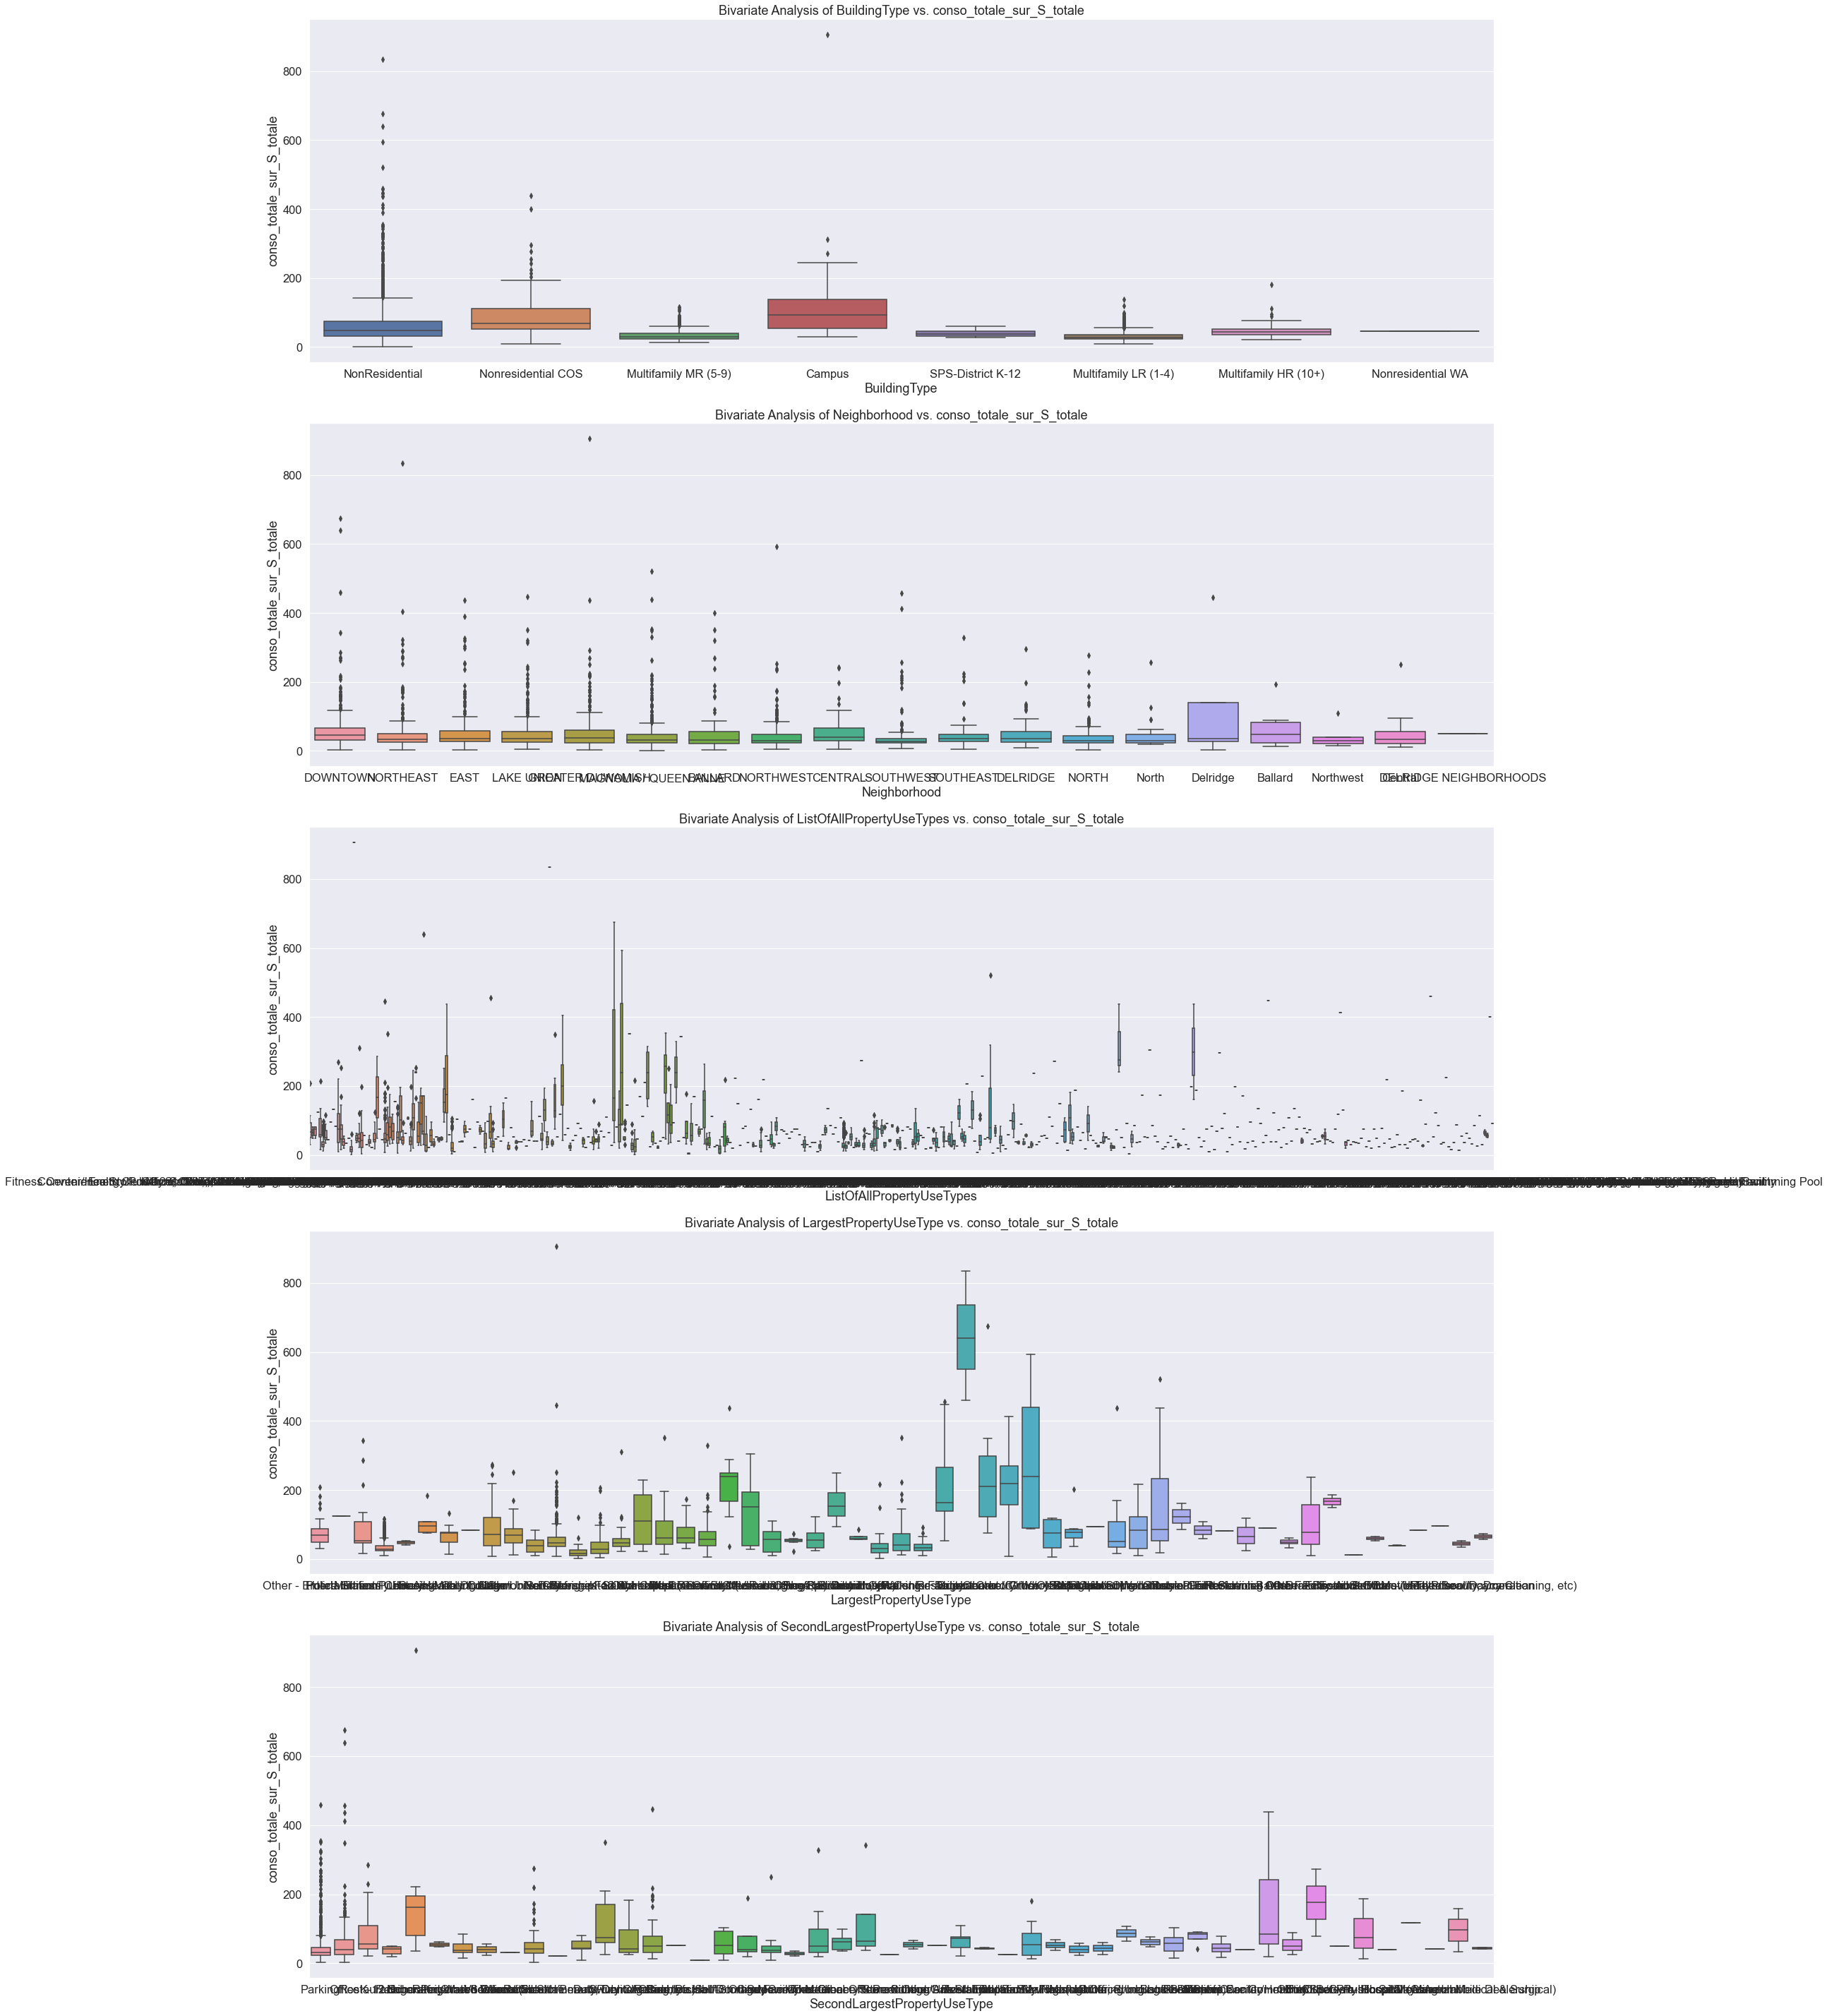

In [82]:
# Create the new column 'emission_totale_sur_S_totale'
data_clean['conso_totale_sur_S_totale'] = data_clean['SiteEnergyUse(kBtu)'] / data_clean['PropertyGFATotal']

# Select qualitative columns
qualitative_columns = data_clean.select_dtypes(include=['object']).columns

sns.set(font_scale=1.5)

# Calculate the number of rows and columns for the subplots
n = len(qualitative_columns)
ncols = 1
nrows = n // ncols + (n % ncols > 0)

# Set the figure size
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))

# Iterate through qualitative_columns and create the boxplots
for idx, column in enumerate(qualitative_columns):
    row, col = idx // ncols, idx % ncols
    sns.boxplot(x=column, y='conso_totale_sur_S_totale', data=data_clean, ax=axes[row])
    chaine = 'Bivariate Analysis of ' + column + ' vs. conso_totale_sur_S_totale'
    axes[row].set_title(chaine)
    axes[row].set_xlabel(column)
    axes[row].set_ylabel('conso_totale_sur_S_totale')

# If there are empty subplots, remove their axes
for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)


## SiteEnergyUse(kBtu) consommation variables quantitatives



In [83]:

quantitative_columns = data_clean.select_dtypes(include=['number']).drop('conso_totale_sur_S_totale', axis=1).columns

sns.set(font_scale=1.5)


n = len(quantitative_columns)
ncols = 1
nrows = n // ncols + (n % ncols > 0)

# Set the figure size
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(35, 8 * nrows))


for idx, column in enumerate(quantitative_columns):
    row, col = idx // ncols, idx % ncols
    sns.scatterplot(x=column, y='conso_totale_sur_S_totale', data=data_clean, ax=axes[row])
    chaine = 'Bivariate Analysis of ' + column + ' vs. conso_totale_sur_S_totale'
    axes[row].set_title(chaine)
    axes[row].set_xlabel(column)
    axes[row].set_ylabel('conso_totale_sur_S_totale')


for idx in range(n, nrows * ncols):
    row, col = idx // ncols, idx % ncols
    fig.delaxes(axes[row])

plt.tight_layout()
plt.show()
sns.set(font_scale=1)

# Dataset gardé pour modélisation initiale

In [113]:
data = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

In [114]:
data_clean = data[~data['BuildingType'].str.contains("Multifamily")] #Filtre sur Building Type pour garder les bâtiments non destinés à l'habitation, 
data_clean = data_clean[~data_clean['PrimaryPropertyType'].str.contains("Multifamily")] 
data_clean.shape

(1665, 46)

In [115]:
data_clean = data_clean[data_clean["Outlier"] != "High outlier"] #suppression des lignes où "Outlier" prend la valeur High

# Suppression de la colonne "Outlier"
data_clean = data_clean.drop(columns=["Outlier"])

print(data_clean.shape)

(1663, 45)


In [116]:
def is_numeric(value):
    return isinstance(value, (int, float, np.number))

def replace_negative_except_columns(x, columns):
    if x.name in columns:
        return x
    return x.apply(lambda v: np.nan if (is_numeric(v) and v < 0) else v) 
# Remplace les valeurs négatives par NaN, sauf pour les colonnes spécifiées
columns_to_keep = ["Longitude", "Latitude", "ZipCode"]
data_clean = data_clean.apply(lambda x: replace_negative_except_columns(x, columns_to_keep))

In [117]:
# Suppression des données non compliant
data_clean = data_clean[~data_clean['ComplianceStatus'].isin(['Error - Correct Default Data', 'Missing Data', 'Non-Compliant'])]
data_clean.drop(columns=['ComplianceStatus'], inplace=True)

In [118]:
data_clean.shape

(1546, 44)

# Imputation des données manquantes

In [119]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

def impute_and_normalize_data(data, target_cols):
    data_clean_before_imputation = data
    data_clean_before_imputation.reset_index(drop=True, inplace=True)
    targets = data_clean_before_imputation[target_cols]

    data_clean_before_imputation = data_clean_before_imputation.drop(target_cols, axis=1)

    # Separate quantitative and qualitative columns
    quantitative_columns = data_clean_before_imputation.select_dtypes(include=['int64', 'float64']).columns
    qualitative_columns = data_clean_before_imputation.select_dtypes(include=['object']).columns

    # Normalize and impute missing values in quantitative columns
    quantitative_data = data_clean_before_imputation[quantitative_columns]
    scaler = StandardScaler()
    quantitative_data_normalized = pd.DataFrame(scaler.fit_transform(quantitative_data), columns=quantitative_columns)
    imputer = KNNImputer(n_neighbors=5)
    quantitative_data_imputed_normalized = imputer.fit_transform(quantitative_data_normalized)
    quantitative_data_imputed = pd.DataFrame(scaler.inverse_transform(quantitative_data_imputed_normalized), columns=quantitative_columns)

    # Combine imputed quantitative columns and qualitative columns
    data_imputed = pd.concat([quantitative_data_imputed.reset_index(drop=True), data_clean_before_imputation[qualitative_columns].reset_index(drop=True)], axis=1)

    # Add the target columns back and remove rows where the targets are missing
    for col in target_cols:
        data_imputed[col] = targets[col]

    data_imputed = data_imputed.dropna(subset=target_cols)

    return data_imputed

In [120]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_imputed = impute_and_normalize_data(data_clean_before_imputation, target_cols)
data_imputed.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,7226362.5
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,8387933.0
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,72587024.0
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,6794584.0
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,14172606.0


## dataset Emission

In [129]:
data_modelisation_em = data_imputed[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","TotalGHGEmissions"]]

In [130]:
data_modelisation_em.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,TotalGHGEmissions
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,249.98
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,295.86
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,2089.28
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,286.43
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,505.01


In [131]:
data_modelisation_em.shape

(1545, 8)

## dataset Consommation

In [133]:
data_modelisation_conso = data_imputed[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","SiteEnergyUse(kBtu)"]]
data_modelisation_conso.shape

(1545, 8)

In [134]:
data_modelisation_conso.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,7226362.5
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,8387933.0
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,72587024.0
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,6794584.0
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,14172606.0
